Attempting to load image pair:
NIR: /kaggle/input/rgbnir-aerial-crop-dataset/Drybean-dataset/Drybean-dataset/drybean-30072020/NIR-1/48.png
RGB: /kaggle/input/rgbnir-aerial-crop-dataset/Drybean-dataset/Drybean-dataset/drybean-30072020/RGB-1/48.png

✅ Image pair found. Loading images...
Resizing NIR image to match RGB dimensions...

Processing image...
Preprocessing metrics -> PSNR: 30.32 | SSIM: 0.9093
💾 Mask saved at: /kaggle/working/vegetation_mask.png
   (You can download it from the Output tab on the right)


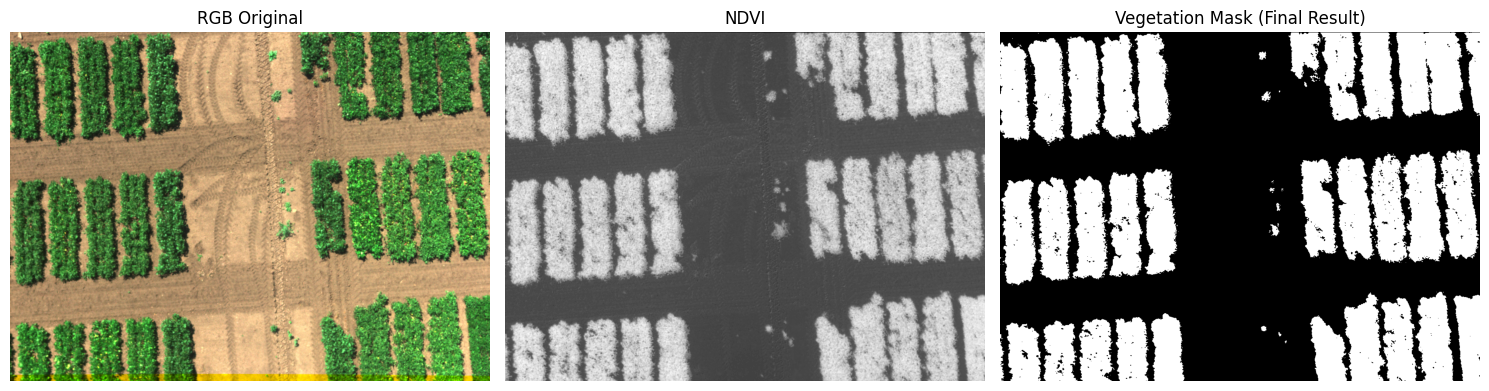

In [7]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# ============================================================
# 1. MANUAL PATH DEFINITION
# ============================================================

# Exact path to an existing NIR image
nir_path = '/kaggle/input/rgbnir-aerial-crop-dataset/Drybean-dataset/Drybean-dataset/drybean-30072020/NIR-1/48.png'

# Try to guess the corresponding RGB path by replacing 'NIR-1' with 'RGB-1'
rgb_path = nir_path.replace('NIR-1', 'RGB-1')

# Fallback: if 'RGB-1' folder doesn't exist, try just 'RGB'
if not os.path.exists(rgb_path):
    rgb_path = nir_path.replace('NIR-1', 'RGB')

print("Attempting to load image pair:")
print(f"NIR: {nir_path}")
print(f"RGB: {rgb_path}")

# ============================================================
# 2. CHECK AND LOAD IMAGES
# ============================================================

if not os.path.exists(rgb_path):
    print("\n❌ Could not find the corresponding RGB folder.")
    print("Please check the exact folder name ('RGB-1' or 'RGB') in the dataset on the right panel.")
else:
    print("\n✅ Image pair found. Loading images...")

    # Load images
    rgb_img = cv2.imread(rgb_path)                    # Color RGB image (BGR format)
    nir_img = cv2.imread(nir_path, cv2.IMREAD_GRAYSCALE)  # Grayscale NIR image

    # ============================================================
    # 3. HELPER FUNCTIONS
    # ============================================================

    def calculate_ndvi(red_channel, nir_channel):
        """Calculate NDVI from Red and NIR bands."""
        red = red_channel.astype(np.float32)
        nir = nir_channel.astype(np.float32)
        
        denominator = nir + red
        denominator[denominator == 0] = 1e-8          # Avoid division by zero
        
        ndvi = (nir - red) / denominator
        
        # Normalize for visualization (0-255)
        ndvi_visual = cv2.normalize(ndvi, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)
        return ndvi, ndvi_visual


    def segment_kmeans_ndvi(ndvi_visual, k=2):
        """Simple K-means segmentation on NDVI image to separate vegetation."""
        pixel_values = ndvi_visual.reshape((-1, 1)).astype(np.float32)
        
        criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
        _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
        
        # Assume the cluster with higher center value is vegetation
        vegetation_cluster = np.argmax(centers)
        mask = (labels == vegetation_cluster).reshape(ndvi_visual.shape).astype(np.uint8) * 255
        return mask


    def apply_median_filter(image):
        """Apply median blur to reduce noise."""
        return cv2.medianBlur(image, 5)


    def calculate_metrics(original, processed):
        """Calculate PSNR and SSIM between original and processed image."""
        p = psnr(original, processed)
        s = ssim(original, processed, data_range=processed.max() - processed.min())
        return p, s

    # ============================================================
    # 4. MAIN PROCESSING PIPELINE
    # ============================================================

    # Ensure both images have the same dimensions
    red_channel = rgb_img[:, :, 2]                    # Extract Red channel (BGR index 2)
    
    if red_channel.shape != nir_img.shape:
        print("Resizing NIR image to match RGB dimensions...")
        nir_img = cv2.resize(nir_img, (red_channel.shape[1], red_channel.shape[0]))

    print("\nProcessing image...")

    # A. Preprocessing (Noise reduction)
    nir_clean = apply_median_filter(nir_img)
    psnr_val, ssim_val = calculate_metrics(nir_img, nir_clean)
    print(f"Preprocessing metrics -> PSNR: {psnr_val:.2f} | SSIM: {ssim_val:.4f}")

    # B. Calculate NDVI
    _, ndvi_visual = calculate_ndvi(red_channel, nir_clean)

    # C. Segmentation (K-means on NDVI)
    vegetation_mask = segment_kmeans_ndvi(ndvi_visual)

    # D. Save the final mask
    save_path = "/kaggle/working/vegetation_mask.png"
    cv2.imwrite(save_path, vegetation_mask)
    print(f"💾 Mask saved at: {save_path}")
    print("   (You can download it from the Output tab on the right)")

    # E. Visualization
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.title("RGB Original")
    plt.imshow(cv2.cvtColor(rgb_img, cv2.COLOR_BGR2RGB))
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title("NDVI")
    plt.imshow(ndvi_visual, cmap='gray')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title("Vegetation Mask (Final Result)")
    plt.imshow(vegetation_mask, cmap='gray')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [1]:
# ============================================================
# FAST Paired Dataset Creator for Pix2Pix (RGB → NIR) + Train/Test Split
# ============================================================
import os
import cv2
import numpy as np
import random
from tqdm import tqdm
import shutil
from concurrent.futures import ThreadPoolExecutor, as_completed

DATASET_INPUT = "/kaggle/input/rgbnir-aerial-crop-dataset"
REPO_DIR = "/kaggle/working/pix2pix_rgb2nir/pytorch-CycleGAN-and-pix2pix"
BASE_DIR = f"{REPO_DIR}/datasets/rgb2nir"

TRAIN_DIR = f"{BASE_DIR}/train"
TEST_DIR  = f"{BASE_DIR}/test"

# Clean old folders
for d in [TRAIN_DIR, TEST_DIR]:
    if os.path.exists(d):
        shutil.rmtree(d)
    os.makedirs(d, exist_ok=True)

print("🔍 Collecting all RGB-NIR pairs...")

paired_list = []   # list of (filename, rgb_path, nir_path)

for root, _, files in os.walk(DATASET_INPUT):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff')):
            nir_path = os.path.join(root, file)
            rgb_path = nir_path.replace('/NIR-', '/RGB-')
            if not os.path.exists(rgb_path):
                rgb_path = nir_path.replace('NIR-1', 'RGB-1')
            
            if os.path.exists(rgb_path):
                # Use original filename as base
                paired_list.append((file, rgb_path, nir_path))

print(f"Found {len(paired_list)} valid pairs.")

# Shuffle and split
random.seed(42)
random.shuffle(paired_list)
split_idx = int(len(paired_list) * 0.8)   # 80% train, 20% test

train_pairs = paired_list[:split_idx]
test_pairs  = paired_list[split_idx:]

def process_and_save(item, output_dir):
    """Process one pair and save (used in parallel)"""
    filename, rgb_path, nir_path = item
    
    rgb = cv2.imread(rgb_path)
    nir = cv2.imread(nir_path, cv2.IMREAD_GRAYSCALE)
    
    if rgb is None or nir is None:
        return False
    
    # Resize NIR to match RGB only if needed
    if rgb.shape[:2] != nir.shape[:2]:
        nir = cv2.resize(nir, (rgb.shape[1], rgb.shape[0]), interpolation=cv2.INTER_LINEAR)
    
    # Convert NIR to 3-channel (required for Pix2Pix paired format)
    nir_3ch = cv2.cvtColor(nir, cv2.COLOR_GRAY2BGR)
    
    # Horizontal stack: RGB | NIR
    paired = np.hstack((rgb, nir_3ch))
    
    save_path = os.path.join(output_dir, filename)
    cv2.imwrite(save_path, paired, [cv2.IMWRITE_JPEG_QUALITY, 95])  # faster with JPEG quality
    return True

# ====================== Parallel Processing ======================
print("🚀 Processing images in parallel (this will be much faster)...")

def save_pairs(pairs, output_dir, desc="Saving"):
    success = 0
    with ThreadPoolExecutor(max_workers=8) as executor:   # adjust 4-12 depending on Kaggle CPU
        futures = [executor.submit(process_and_save, item, output_dir) for item in pairs]
        for future in tqdm(as_completed(futures), total=len(futures), desc=desc):
            if future.result():
                success += 1
    return success

train_success = save_pairs(train_pairs, TRAIN_DIR, "Saving Train")
test_success  = save_pairs(test_pairs,  TEST_DIR,  "Saving Test ")

print("\n🎉 Fast dataset preparation finished!")
print(f"Train images : {train_success} → {TRAIN_DIR}")
print(f"Test images  : {test_success}  → {TEST_DIR}")
print(f"Total time should now be 3–8x faster than before.")

🔍 Collecting all RGB-NIR pairs...
Found 17940 valid pairs.
🚀 Processing images in parallel (this will be much faster)...


Saving Test : 100%|██████████| 3588/3588 [03:15<00:00, 18.39it/s]


🎉 Fast dataset preparation finished!
Train images : 14352 → /kaggle/working/pix2pix_rgb2nir/pytorch-CycleGAN-and-pix2pix/datasets/rgb2nir/train
Test images  : 3588  → /kaggle/working/pix2pix_rgb2nir/pytorch-CycleGAN-and-pix2pix/datasets/rgb2nir/test
Total time should now be 3–8x faster than before.


In [14]:
# ============================================================
# FULL FIXED TRAINING SCRIPT with NDVI Loss + Fine-tuning
# ============================================================
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision.transforms import functional as TF
from PIL import Image
from tqdm import tqdm
import glob
import random

# Memory optimization
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# ========================== SETTINGS ==========================
BATCH_SIZE = 6
EPOCHS = 40
LR = 0.00005
LAMBDA_L1 = 150
LAMBDA_NDVI = 0.8
IMAGE_SIZE = 256

CHECKPOINT_PATH = "/kaggle/input/models/chitranshdamedhar/rgb2nir-generator-pth/pytorch/default/1/rgb2nir_generator_epoch60.pth"   # ← Change if needed

# ========================== DATASET with Augmentations ==========================
class PairedDataset(Dataset):
    def __init__(self, image_paths):
        self.image_paths = image_paths
        self.transform = transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('RGB')
        w = img.width // 2
        rgb = img.crop((0, 0, w, img.height))
        nir = img.crop((w, 0, img.width, img.height))

        rgb = self.transform(rgb)
        nir = transforms.Grayscale()(self.transform(nir))

        # Augmentations
        if random.random() > 0.5:
            rgb = TF.hflip(rgb)
            nir = TF.hflip(nir)
        if random.random() > 0.5:
            rgb = TF.vflip(rgb)
            nir = TF.vflip(nir)
        if random.random() > 0.6:
            angle = random.choice([90, 180, 270])
            rgb = TF.rotate(rgb, angle)
            nir = TF.rotate(nir, angle)

        return rgb, nir


PAIRED_DIR = "/kaggle/working/pix2pix_rgb2nir/pytorch-CycleGAN-and-pix2pix/datasets/rgb2nir/train"
image_paths = sorted(glob.glob(f"{PAIRED_DIR}/*.png")) + sorted(glob.glob(f"{PAIRED_DIR}/*.jpg"))

dataset = PairedDataset(image_paths)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, 
                       num_workers=2, pin_memory=True, drop_last=True)

print(f"Dataset loaded: {len(dataset)} images")

# ========================== EFFICIENT GENERATOR (Fixed) ==========================
class EfficientUNetGenerator(nn.Module):
    def __init__(self, base_channels=40):
        super().__init__()
        bc = base_channels
        
        # Encoder
        self.enc1 = self._down_block(3, bc)
        self.enc2 = self._down_block(bc, bc*2)
        self.enc3 = self._down_block(bc*2, bc*4)
        
        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4),
            nn.ReLU(inplace=True),
        )
        
        # Decoder
        self.up3 = nn.ConvTranspose2d(bc*4, bc*2, 4, 2, 1)
        self.dec3 = self._up_block(bc*4, bc*2)
        
        self.up2 = nn.ConvTranspose2d(bc*2, bc, 4, 2, 1)
        self.dec2 = self._up_block(bc*2, bc)
        
        self.final = nn.Sequential(
            nn.ConvTranspose2d(bc, bc//2, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc//2, 1, 3, padding=1),
            nn.Tanh()
        )

    def _down_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True),
        )

    def _up_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        
        b = self.bottleneck(e3)
        
        d3 = self.up3(b)
        d3 = torch.cat([d3, e2], dim=1)
        d3 = self.dec3(d3)
        
        d2 = self.up2(d3)
        d2 = torch.cat([d2, e1], dim=1)
        d2 = self.dec2(d2)
        
        out = self.final(d2)
        return out


# ========================== MODEL SETUP ==========================
G = EfficientUNetGenerator(base_channels=40).to(DEVICE)

# Load previous checkpoint
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
G.load_state_dict(checkpoint)
G.train()

print(f"✅ Successfully loaded model from {CHECKPOINT_PATH}")

# ========================== DISCRIMINATOR ==========================
class PatchGAN(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(4, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(256, 1, 4, 1, 1)
        )
    def forward(self, x):
        return self.model(x)

D = PatchGAN().to(DEVICE)

# ========================== LOSSES & OPTIMIZERS ==========================
criterion_GAN = nn.MSELoss()
criterion_L1 = nn.L1Loss()

def ndvi_loss(fake_nir, rgb):
    red = rgb[:, 0:1, :, :]
    ndvi_pred = (fake_nir - red) / (fake_nir + red + 1e-6)
    target = torch.clamp(ndvi_pred, -0.2, 0.9)
    return nn.L1Loss()(ndvi_pred, target)

optimizer_G = optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
optimizer_D = optim.Adam(D.parameters(), lr=LR * 0.5, betas=(0.5, 0.999))

# ========================== TRAINING ==========================
print("🚀 Starting fine-tuning with NDVI loss...")

for epoch in range(EPOCHS):
    G.train()
    D.train()
    total_g = 0.0
    total_ndvi = 0.0

    for i, (rgb, nir) in enumerate(tqdm(dataloader)):
        rgb = rgb.to(DEVICE)
        nir = nir.to(DEVICE)

        # Discriminator
        optimizer_D.zero_grad()
        fake_nir = G(rgb)
        real_pair = torch.cat((rgb, nir), dim=1)
        fake_pair = torch.cat((rgb, fake_nir.detach()), dim=1)

        loss_D = 0.5 * (criterion_GAN(D(real_pair), torch.ones_like(D(real_pair))) +
                        criterion_GAN(D(fake_pair), torch.zeros_like(D(fake_pair))))
        loss_D.backward()
        optimizer_D.step()

        # Generator
        optimizer_G.zero_grad()
        pred_fake = D(torch.cat((rgb, fake_nir), dim=1))
        
        loss_G_GAN = criterion_GAN(pred_fake, torch.ones_like(pred_fake))
        loss_G_L1 = criterion_L1(fake_nir, nir)
        loss_G_NDVI = ndvi_loss(fake_nir, rgb)
        
        loss_G = loss_G_GAN + LAMBDA_L1 * loss_G_L1 + LAMBDA_NDVI * loss_G_NDVI
        loss_G.backward()
        optimizer_G.step()

        total_g += loss_G.item()
        total_ndvi += loss_G_NDVI.item()

        if i % 50 == 0:
            print(f"Batch {i} | G: {loss_G.item():.4f} | NDVI: {loss_G_NDVI.item():.4f}")

    print(f"Epoch {epoch+1}/{EPOCHS} | Avg G_loss: {total_g/len(dataloader):.4f} | NDVI_loss: {total_ndvi/len(dataloader):.4f}")

    if (epoch + 1) % 10 == 0:
        torch.save(G.state_dict(), f"/kaggle/working/improved_ndvi_epoch{epoch+1}.pth")
        print(f"✅ Model saved: improved_ndvi_epoch{epoch+1}.pth")

print("\n🎉 Fine-tuning completed!")

Using device: cuda
Dataset loaded: 1976 images


OutOfMemoryError: CUDA out of memory. Tried to allocate 20.00 MiB. GPU 0 has a total capacity of 15.89 GiB of which 29.12 MiB is free. Process 3211 has 15.86 GiB memory in use. Of the allocated memory 15.56 GiB is allocated by PyTorch, and 16.33 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

Using device: cuda
Model path   : /kaggle/input/models/chitranshdamedhar/rgb2nir-generator-pth/pytorch/default/1/rgb2nir_generator_epoch60.pth

Loading model...
✅ Model loaded successfully!

Found 1213 test images.



  0%|          | 1/1213 [00:02<48:45,  2.41s/it]

✓ Saved: /kaggle/working/test_results_ndvi/test_0000_0_NDVI_result.jpg


  0%|          | 2/1213 [00:04<40:37,  2.01s/it]

✓ Saved: /kaggle/working/test_results_ndvi/test_0001_1_NDVI_result.jpg


...

  6%|▌         | 73/1213 [01:52<28:47,  1.51s/it]

✓ Saved: /kaggle/working/test_results_ndvi/test_0072_163_NDVI_result.jpg


  6%|▌         | 74/1213 [01:54<29:21,  1.55s/it]

✓ Saved: /kaggle/working/test_results_ndvi/test_0073_164_NDVI_result.jpg


KeyboardInterrupt: 

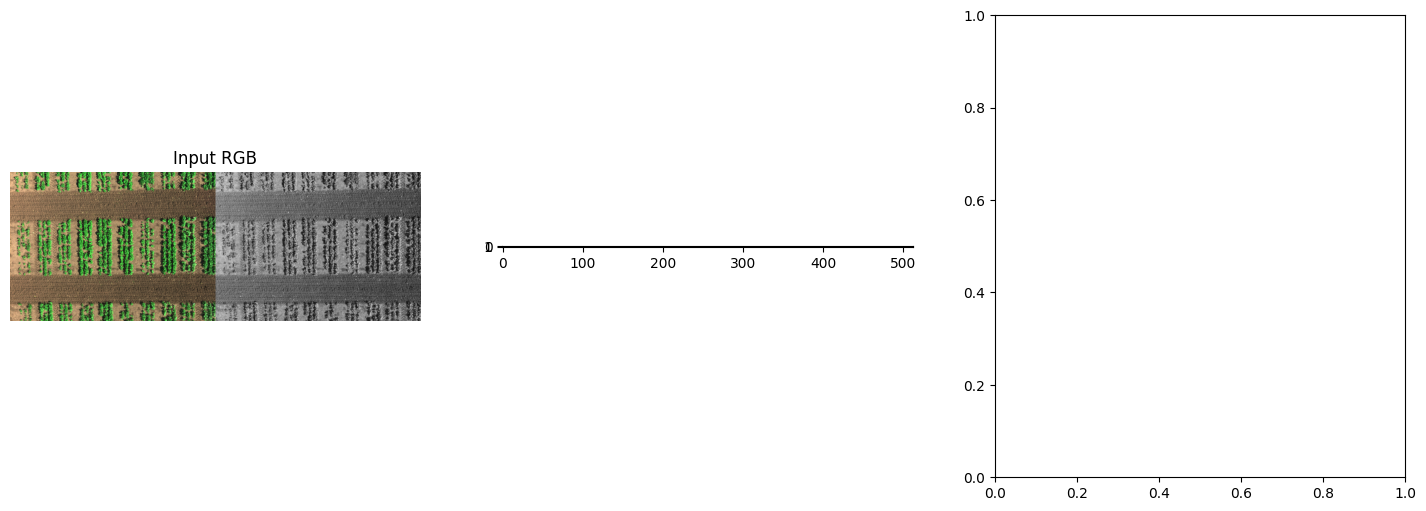

In [3]:
# ============================================================
# FIXED & IMPROVED Pix2Pix RGB → NIR Inference with NDVI
# ============================================================
import os
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import glob
from tqdm import tqdm
import cv2

# ========================== SETTINGS ==========================
MODEL_PATH = "/kaggle/input/models/chitranshdamedhar/rgb2nir-generator-pth/pytorch/default/1/rgb2nir_generator_epoch60.pth"
TEST_DIR = "/kaggle/working/pix2pix_rgb2nir/pytorch-CycleGAN-and-pix2pix/datasets/rgb2nir/test"
OUTPUT_DIR = "/kaggle/working/test_results_ndvi"

SAVE_NPY = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Using device: {DEVICE}")
print(f"Model path   : {MODEL_PATH}\n")

# ========================== TRANSFORMS ==========================
transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# ========================== MODEL DEFINITION ==========================
class UNetGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 512, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(512, 256, 4, 2, 1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


# ========================== LOAD MODEL ==========================
print("Loading model...")
G = UNetGenerator().to(DEVICE)

try:
    state_dict = torch.load(MODEL_PATH, map_location=DEVICE)
    G.load_state_dict(state_dict)
    G.eval()
    print("✅ Model loaded successfully!\n")
except Exception as e:
    print(f"❌ Failed to load model: {e}")
    exit()


# ========================== INFERENCE FUNCTION ==========================
def infer_image(image_path, save_name):
    try:
        # Load image
        img = Image.open(image_path).convert('RGB')
        original_np = np.array(img)

        # Transform
        input_tensor = transform(img).unsqueeze(0).to(DEVICE)

        # Forward pass
        with torch.no_grad():
            fake_nir = G(input_tensor)

        # Denormalize [-1,1] → [0,1]
        fake_nir = (fake_nir * 0.5 + 0.5).clamp(0, 1)
        fake_nir_np = fake_nir.squeeze(0).squeeze(0).cpu().numpy()

        # Save NIR
        if SAVE_NPY:
            np.save(os.path.join(OUTPUT_DIR, f"{save_name}_NIR.npy"), fake_nir_np)

        # ========================== NDVI ==========================
        rgb_resized = cv2.resize(original_np, (512, 512))
        R = rgb_resized[:, :, 0].astype(np.float32) / 255.0
        nir = fake_nir_np

        ndvi = (nir - R) / (nir + R + 1e-6)
        ndvi = np.clip(ndvi, -1.0, 1.0)

        # ========================== VISUALIZATION ==========================
        fig, axs = plt.subplots(1, 3, figsize=(18, 6))

        axs[0].imshow(original_np)
        axs[0].set_title("Input RGB")
        axs[0].axis('off')

        axs[1].imshow(fake_nir_np, cmap='gray')
        axs[1].set_title("Generated NIR")
        axs[1].axis('off')

        im = axs[2].imshow(ndvi, cmap='RdYlGn', vmin=-0.2, vmax=0.9)
        axs[2].set_title("NDVI Map\n(Green = Healthy | Red = Stressed)")
        axs[2].axis('off')
        fig.colorbar(im, ax=axs[2], fraction=0.046, pad=0.04)

        plt.tight_layout()
        vis_path = os.path.join(OUTPUT_DIR, f"{save_name}_NDVI_result.jpg")
        plt.savefig(vis_path, dpi=220, bbox_inches='tight')
        plt.close()

        np.save(os.path.join(OUTPUT_DIR, f"{save_name}_NDVI.npy"), ndvi)

        print(f"✓ Saved: {vis_path}")
        return fake_nir_np, ndvi

    except Exception as e:
        print(f"❌ Error processing {os.path.basename(image_path)}: {e}")
        return None, None


# ========================== RUN INFERENCE ==========================
image_paths = sorted(glob.glob(f"{TEST_DIR}/*.png")) + sorted(glob.glob(f"{TEST_DIR}/*.jpg"))

print(f"Found {len(image_paths)} test images.\n")

for idx, path in enumerate(tqdm(image_paths)):
    base_name = os.path.splitext(os.path.basename(path))[0]
    infer_image(path, f"test_{idx:04d}_{base_name}")

print(f"\n🎉 Inference completed!")
print(f"Results saved in: {OUTPUT_DIR}")

In [2]:
# ============================================================
# COMPLETE TRAINING SCRIPT - Load .pth + Fine-tune with NDVI Loss
# ============================================================
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision.transforms import functional as TF
from PIL import Image
from tqdm import tqdm
import glob
import random

# ====================== MEMORY OPTIMIZATION ======================
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# ====================== SETTINGS ======================
BATCH_SIZE = 16
EPOCHS = 40
LR = 0.00005
LAMBDA_L1 = 150
LAMBDA_NDVI = 0.8
IMAGE_SIZE = 256

CHECKPOINT_PATH = "/kaggle/working/rgb2nir_generator_epoch60.pth"   # ← Change if your file name is different

# ====================== DATASET ======================
PAIRED_DIR = "/kaggle/working/pix2pix_rgb2nir/pytorch-CycleGAN-and-pix2pix/datasets/rgb2nir/train"

image_paths = sorted(glob.glob(f"{PAIRED_DIR}/*.png")) + sorted(glob.glob(f"{PAIRED_DIR}/*.jpg"))
print(f"Found {len(image_paths)} paired images.")

if len(image_paths) == 0:
    raise ValueError("No images found in train folder! Run the pairing script first.")

class PairedDataset(Dataset):
    def __init__(self, image_paths):
        self.image_paths = image_paths
        self.transform = transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('RGB')
        w = img.width // 2
        rgb = img.crop((0, 0, w, img.height))
        nir = img.crop((w, 0, img.width, img.height))

        rgb = self.transform(rgb)
        nir = transforms.Grayscale()(self.transform(nir))

        # Simple augmentation
        if random.random() > 0.5:
            rgb = TF.hflip(rgb)
            nir = TF.hflip(nir)

        return rgb, nir


dataset = PairedDataset(image_paths)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, 
                       num_workers=2, pin_memory=True, drop_last=True)

print(f"✅ Dataloader ready with {len(dataset)} images")

# ====================== MODEL DEFINITION ======================
class EfficientUNetGenerator(nn.Module):
    def __init__(self, base_channels=40):
        super().__init__()
        bc = base_channels
        
        # Encoder
        self.enc1 = self._down_block(3, bc)
        self.enc2 = self._down_block(bc, bc*2)
        self.enc3 = self._down_block(bc*2, bc*4)
        
        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4),
            nn.ReLU(inplace=True),
        )
        
        # Decoder with skips
        self.up3 = nn.ConvTranspose2d(bc*4, bc*2, 4, 2, 1)
        self.dec3 = self._up_block(bc*4, bc*2)
        
        self.up2 = nn.ConvTranspose2d(bc*2, bc, 4, 2, 1)
        self.dec2 = self._up_block(bc*2, bc)
        
        self.final = nn.Sequential(
            nn.ConvTranspose2d(bc, bc//2, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc//2, 1, 3, padding=1),
            nn.Tanh()
        )

    def _down_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True),
        )

    def _up_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        b = self.bottleneck(e3)
        d3 = self.up3(b)
        d3 = torch.cat([d3, e2], dim=1)
        d3 = self.dec3(d3)
        d2 = self.up2(d3)
        d2 = torch.cat([d2, e1], dim=1)
        d2 = self.dec2(d2)
        out = self.final(d2)
        return out


# ====================== LOAD MODEL ======================
G = EfficientUNetGenerator(base_channels=40).to(DEVICE)

if os.path.exists(CHECKPOINT_PATH):
    G.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE))
    print(f"✅ Successfully loaded .pth file: {CHECKPOINT_PATH}")
else:
    print(f"⚠️ Warning: {CHECKPOINT_PATH} not found. Training from scratch.")

# ====================== DISCRIMINATOR ======================
class PatchGAN(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(4, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(256, 1, 4, 1, 1)
        )
    def forward(self, x):
        return self.model(x)

D = PatchGAN().to(DEVICE)

# ====================== LOSSES ======================
criterion_GAN = nn.MSELoss()
criterion_L1 = nn.L1Loss()

def ndvi_loss(fake_nir, rgb):
    red = rgb[:, 0:1, :, :]
    ndvi_pred = (fake_nir - red) / (fake_nir + red + 1e-6)
    target = torch.clamp(ndvi_pred, -0.2, 0.9)
    return nn.L1Loss()(ndvi_pred, target)

# ====================== OPTIMIZERS ======================
optimizer_G = optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
optimizer_D = optim.Adam(D.parameters(), lr=LR * 0.5, betas=(0.5, 0.999))

# ====================== TRAINING LOOP ======================
print("\n🚀 Starting Fine-tuning...\n")

for epoch in range(EPOCHS):
    G.train()
    D.train()
    total_loss_g = 0.0
    total_ndvi = 0.0

    for i, (rgb, nir) in enumerate(tqdm(dataloader)):
        rgb = rgb.to(DEVICE)
        nir = nir.to(DEVICE)

        # Train Discriminator
        optimizer_D.zero_grad()
        fake_nir = G(rgb)
        real_pair = torch.cat((rgb, nir), dim=1)
        fake_pair = torch.cat((rgb, fake_nir.detach()), dim=1)

        loss_D = 0.5 * (criterion_GAN(D(real_pair), torch.ones_like(D(real_pair))) +
                        criterion_GAN(D(fake_pair), torch.zeros_like(D(fake_pair))))
        loss_D.backward()
        optimizer_D.step()

        # Train Generator
        optimizer_G.zero_grad()
        pred_fake = D(torch.cat((rgb, fake_nir), dim=1))
        
        loss_G_GAN = criterion_GAN(pred_fake, torch.ones_like(pred_fake))
        loss_G_L1 = criterion_L1(fake_nir, nir)
        loss_G_NDVI = ndvi_loss(fake_nir, rgb)
        
        loss_G = loss_G_GAN + LAMBDA_L1 * loss_G_L1 + LAMBDA_NDVI * loss_G_NDVI
        
        loss_G.backward()
        optimizer_G.step()

        total_loss_g += loss_G.item()
        total_ndvi += loss_G_NDVI.item()

        if i % 50 == 0:
            print(f"  Batch {i:3d} | G_loss: {loss_G.item():.4f} | NDVI_loss: {loss_G_NDVI.item():.4f}")

    avg_g = total_loss_g / len(dataloader)
    avg_ndvi = total_ndvi / len(dataloader)
    
    print(f"Epoch [{epoch+1:2d}/{EPOCHS}] | Avg G_loss: {avg_g:.4f} | Avg NDVI_loss: {avg_ndvi:.4f}")

    # Save model every 10 epochs
    if (epoch + 1) % 10 == 0 or epoch == EPOCHS-1:
        save_path = f"/kaggle/working/finetuned_epoch{epoch+1}.pth"
        torch.save(G.state_dict(), save_path)
        print(f"✅ Model saved: {save_path}")

print("\n🎉 Training Completed!")

Using device: cuda
Found 1976 paired images.
✅ Dataloader ready with 1976 images
⚠️ Warning: /kaggle/working/rgb2nir_generator_epoch60.pth not found. Training from scratch.

🚀 Starting Fine-tuning...



  1%|          | 1/123 [00:04<08:54,  4.38s/it]

  Batch   0 | G_loss: 68.4293 | NDVI_loss: 4.5190


 41%|████▏     | 51/123 [00:31<00:35,  2.04it/s]

  Batch  50 | G_loss: 71.2610 | NDVI_loss: 3.3912


...

  Batch  50 | G_loss: 100.2899 | NDVI_loss: 12.4958


 82%|████████▏ | 101/123 [00:53<00:10,  2.11it/s]

  Batch 100 | G_loss: 112.0032 | NDVI_loss: 13.6465


100%|██████████| 123/123 [01:05<00:00,  1.86it/s]

Epoch [40/40] | Avg G_loss: 104.8102 | Avg NDVI_loss: 17.1496
✅ Model saved: /kaggle/working/finetuned_epoch40.pth

🎉 Training Completed!


✅ Loaded model: /kaggle/input/models/chitranshdamedhar/finetunedmodel-40-epoch/pytorch/default/1/finetuned_epoch40.pth


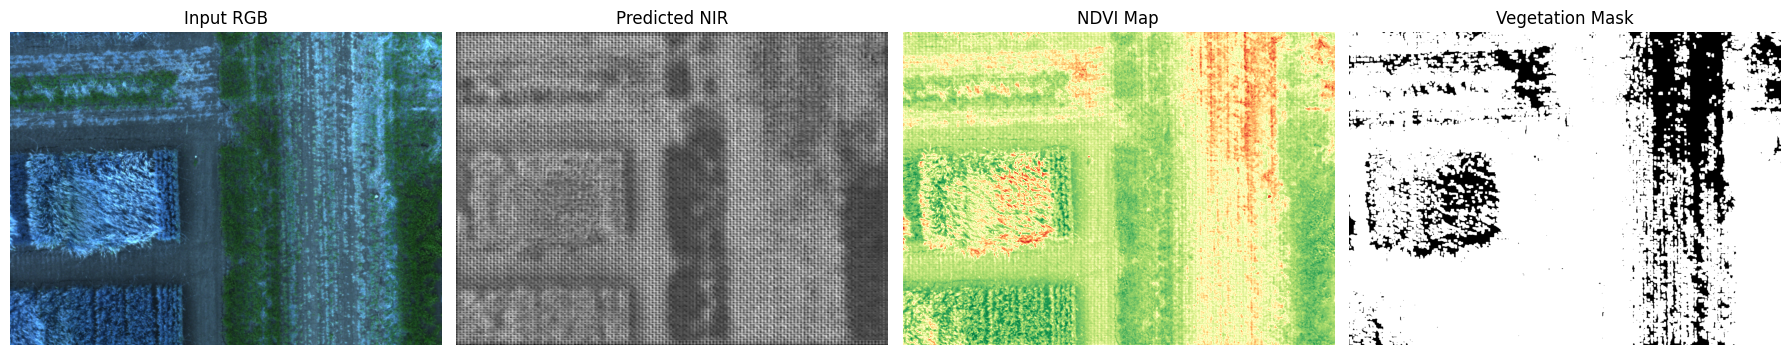

Mean NDVI: 0.524
Vegetation Coverage: 82.7%


In [4]:
# ============================================================
# INFERENCE SCRIPT - Test Your Fine-tuned Model
# ============================================================
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ====================== MODEL ======================
class EfficientUNetGenerator(nn.Module):
    def __init__(self, base_channels=40):
        super().__init__()
        bc = base_channels
        self.enc1 = self._down_block(3, bc)
        self.enc2 = self._down_block(bc, bc*2)
        self.enc3 = self._down_block(bc*2, bc*4)
        
        self.bottleneck = nn.Sequential(
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4),
            nn.ReLU(inplace=True),
        )
        
        self.up3 = nn.ConvTranspose2d(bc*4, bc*2, 4, 2, 1)
        self.dec3 = self._up_block(bc*4, bc*2)
        self.up2 = nn.ConvTranspose2d(bc*2, bc, 4, 2, 1)
        self.dec2 = self._up_block(bc*2, bc)
        
        self.final = nn.Sequential(
            nn.ConvTranspose2d(bc, bc//2, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc//2, 1, 3, padding=1),
            nn.Tanh()
        )

    def _down_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True),
        )

    def _up_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        b = self.bottleneck(e3)
        d3 = self.up3(b)
        d3 = torch.cat([d3, e2], dim=1)
        d3 = self.dec3(d3)
        d2 = self.up2(d3)
        d2 = torch.cat([d2, e1], dim=1)
        d2 = self.dec2(d2)
        out = self.final(d2)
        return out


# Load your latest model
MODEL_PATH = "/kaggle/input/models/chitranshdamedhar/finetunedmodel-40-epoch/pytorch/default/1/finetuned_epoch40.pth"

G = EfficientUNetGenerator(base_channels=40).to(DEVICE)
G.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
G.eval()

print(f"✅ Loaded model: {MODEL_PATH}")

# ====================== TRANSFORM ======================
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# ====================== TEST FUNCTION ======================
def test_model(rgb_path):
    rgb_pil = Image.open(rgb_path).convert('RGB')
    original_rgb = np.array(rgb_pil)
    
    input_tensor = transform(rgb_pil).unsqueeze(0).to(DEVICE)
    
    with torch.no_grad():
        fake_nir = G(input_tensor)
        fake_nir = (fake_nir * 0.5 + 0.5).clamp(0, 1)
        fake_nir_np = fake_nir.squeeze().cpu().numpy()
    
    # Resize back to original size
    h, w = original_rgb.shape[:2]
    fake_nir_resized = cv2.resize(fake_nir_np, (w, h))
    
    # NDVI
    red = original_rgb[:, :, 2].astype(np.float32) / 255.0
    nir = fake_nir_resized
    ndvi = (nir - red) / (nir + red + 1e-6)
    ndvi = np.clip(ndvi, -1.0, 1.0)
    
    ndvi_vis = cv2.normalize(ndvi, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)
    
    # Vegetation Mask
    _, mask = cv2.threshold(ndvi_vis, 110, 255, cv2.THRESH_BINARY)
    kernel = np.ones((5,5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    
    # Save
    cv2.imwrite("/kaggle/working/pred_nir.png", (fake_nir_resized*255).astype(np.uint8))
    cv2.imwrite("/kaggle/working/ndvi.png", ndvi_vis)
    cv2.imwrite("/kaggle/working/vegetation_mask.png", mask)
    
    # Show
    plt.figure(figsize=(18, 5))
    plt.subplot(1, 4, 1)
    plt.title("Input RGB")
    plt.imshow(cv2.cvtColor(original_rgb, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    
    plt.subplot(1, 4, 2)
    plt.title("Predicted NIR")
    plt.imshow(fake_nir_resized, cmap='gray')
    plt.axis('off')
    
    plt.subplot(1, 4, 3)
    plt.title("NDVI Map")
    plt.imshow(ndvi_vis, cmap='RdYlGn')
    plt.axis('off')
    
    plt.subplot(1, 4, 4)
    plt.title("Vegetation Mask")
    plt.imshow(mask, cmap='gray')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print(f"Mean NDVI: {np.mean(ndvi):.3f}")
    print(f"Vegetation Coverage: {(np.sum(mask > 128) / mask.size * 100):.1f}%")

# ====================== RUN TEST ======================
# Change this path to any RGB image you want to test
test_rgb_path = "/kaggle/input/rgbnir-aerial-crop-dataset/Wheat-dataset/Wheat-dataset/wheat_30082019/RGB/1000.png"

test_model(test_rgb_path)

In [4]:
# ============================================================
# RANDOM TEST SCRIPT - For Evaluators (Selective Testing)
# ============================================================
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
import glob
import random
from tqdm import tqdm

# ====================== SETTINGS ======================
MODEL_PATH = "/kaggle/working/finetuned_epoch40.pth"
TEST_DIR = "/kaggle/working/pix2pix_rgb2nir/pytorch-CycleGAN-and-pix2pix/datasets/rgb2nir/test"
OUTPUT_DIR = "/kaggle/working/random_evaluation_results"

NUM_SAMPLES = 8          # ← Change this: how many random images you want to test
RANDOM_SEED = 42         # For reproducibility

os.makedirs(OUTPUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Testing model : {MODEL_PATH}")
print(f"Sampling {NUM_SAMPLES} random images from test set...\n")

# ====================== MODEL ======================
class EfficientUNetGenerator(nn.Module):
    def __init__(self, base_channels=40):
        super().__init__()
        bc = base_channels
        self.enc1 = self._down_block(3, bc)
        self.enc2 = self._down_block(bc, bc*2)
        self.enc3 = self._down_block(bc*2, bc*4)
        
        self.bottleneck = nn.Sequential(
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4), nn.ReLU(inplace=True),
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4), nn.ReLU(inplace=True),
        )
        
        self.up3 = nn.ConvTranspose2d(bc*4, bc*2, 4, 2, 1)
        self.dec3 = self._up_block(bc*4, bc*2)
        self.up2 = nn.ConvTranspose2d(bc*2, bc, 4, 2, 1)
        self.dec2 = self._up_block(bc*2, bc)
        
        self.final = nn.Sequential(
            nn.ConvTranspose2d(bc, bc//2, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc//2, 1, 3, padding=1),
            nn.Tanh()
        )

    def _down_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True),
        )

    def _up_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        b = self.bottleneck(e3)
        d3 = torch.cat([self.up3(b), e2], 1)
        d3 = self.dec3(d3)
        d2 = torch.cat([self.up2(d3), e1], 1)
        d2 = self.dec2(d2)
        return self.final(d2)


# Load Model
G = EfficientUNetGenerator(base_channels=40).to(DEVICE)
G.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
G.eval()
print("✅ Model loaded successfully!\n")

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# ====================== INFERENCE FUNCTION ======================
def process_image(rgb_path, save_name):
    rgb_pil = Image.open(rgb_path).convert('RGB')
    original = np.array(rgb_pil)
    
    input_tensor = transform(rgb_pil).unsqueeze(0).to(DEVICE)
    
    with torch.no_grad():
        pred = G(input_tensor)
        pred_nir = (pred * 0.5 + 0.5).clamp(0, 1).squeeze().cpu().numpy()
    
    h, w = original.shape[:2]
    pred_nir = cv2.resize(pred_nir, (w, h))
    
    red = original[:, :, 2].astype(np.float32) / 255.0
    ndvi = (pred_nir - red) / (pred_nir + red + 1e-6)
    ndvi = np.clip(ndvi, -1.0, 1.0)
    
    ndvi_vis = cv2.normalize(ndvi, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)
    
    _, mask = cv2.threshold(ndvi_vis, 105, 255, cv2.THRESH_BINARY)
    kernel = np.ones((5,5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    
    # Save results
    cv2.imwrite(f"{OUTPUT_DIR}/{save_name}_RGB.jpg", cv2.cvtColor(original, cv2.COLOR_RGB2BGR))
    cv2.imwrite(f"{OUTPUT_DIR}/{save_name}_Predicted_NIR.png", (pred_nir * 255).astype(np.uint8))
    cv2.imwrite(f"{OUTPUT_DIR}/{save_name}_NDVI.png", ndvi_vis)
    cv2.imwrite(f"{OUTPUT_DIR}/{save_name}_Mask.png", mask)
    
    # Summary visualization for evaluators
    fig, axs = plt.subplots(1, 4, figsize=(20, 5))
    axs[0].imshow(original)
    axs[0].set_title("Input RGB")
    axs[0].axis('off')
    
    axs[1].imshow(pred_nir, cmap='gray')
    axs[1].set_title("Predicted NIR")
    axs[1].axis('off')
    
    axs[2].imshow(ndvi_vis, cmap='RdYlGn')
    axs[2].set_title(f"NDVI Map\nMean: {np.mean(ndvi):.3f}")
    axs[2].axis('off')
    
    axs[3].imshow(mask, cmap='gray')
    axs[3].set_title(f"Vegetation Mask\nCoverage: {(np.sum(mask>128)/mask.size*100):.1f}%")
    axs[3].axis('off')
    
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/{save_name}_Summary.jpg", dpi=220, bbox_inches='tight')
    plt.close()
    
    return np.mean(ndvi), (np.sum(mask > 128) / mask.size * 100)


# ====================== RANDOM SAMPLING ======================
random.seed(RANDOM_SEED)

test_images = sorted(glob.glob(f"{TEST_DIR}/*.png")) + sorted(glob.glob(f"{TEST_DIR}/*.jpg"))

if len(test_images) == 0:
    raise ValueError("No test images found!")

# Randomly select NUM_SAMPLES images
selected_images = random.sample(test_images, min(NUM_SAMPLES, len(test_images)))

print(f"Randomly selected {len(selected_images)} images for evaluation.\n")

results = []
for idx, img_path in enumerate(tqdm(selected_images)):
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    mean_ndvi, coverage = process_image(img_path, f"random_eval_{idx:02d}_{base_name}")
    results.append((base_name, mean_ndvi, coverage))

# ====================== SUMMARY REPORT ======================
print("\n" + "="*70)
print("RANDOM EVALUATION SUMMARY (For Evaluators)")
print("="*70)

avg_ndvi = np.mean([r[1] for r in results])
avg_coverage = np.mean([r[2] for r in results])

print(f"Total images tested     : {len(results)}")
print(f"Average NDVI            : {avg_ndvi:.3f}")
print(f"Average Vegetation Coverage : {avg_coverage:.1f}%")
print(f"Results folder          : {OUTPUT_DIR}")
print("="*70)

# Save summary report
with open(f"{OUTPUT_DIR}/SUMMARY_REPORT.txt", "w") as f:
    f.write("Random Evaluation Report - RGB to NIR Translation\n")
    f.write("="*60 + "\n\n")
    f.write(f"Model used          : {os.path.basename(MODEL_PATH)}\n")
    f.write(f"Images tested       : {len(results)}\n")
    f.write(f"Average NDVI        : {avg_ndvi:.3f}\n")
    f.write(f"Average Coverage    : {avg_coverage:.1f}%\n\n")
    f.write("Detailed Results:\n")
    for name, ndvi, cov in results:
        f.write(f"{name:35s} | NDVI: {ndvi:.3f} | Coverage: {cov:.1f}%\n")

print("\n✅ Evaluation completed!")
print(f"All results saved in: {OUTPUT_DIR}")
print("You can now download this folder to present to your evaluators.")

Testing model : /kaggle/working/finetuned_epoch40.pth
Sampling 8 random images from test set...

✅ Model loaded successfully!

Randomly selected 8 images for evaluation.



100%|██████████| 8/8 [00:10<00:00,  1.29s/it]


RANDOM EVALUATION SUMMARY (For Evaluators)
Total images tested     : 8
Average NDVI            : 0.449
Average Vegetation Coverage : 81.1%
Results folder          : /kaggle/working/random_evaluation_results

✅ Evaluation completed!
All results saved in: /kaggle/working/random_evaluation_results
You can now download this folder to present to your evaluators.


In [6]:
# ============================================================
# SIMPLE MANUAL TEST SCRIPT - Give Your Own Image
# ============================================================
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

# ====================== SETTINGS ======================
MODEL_PATH = "/kaggle/input/rgbnir-aerial-crop-dataset/Wheat-dataset/Wheat-dataset/wheat_30082019/RGB/1000.png"   # Change if needed
OUTPUT_DIR = "/kaggle/working/manual_test_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ====================== MODEL ======================
class EfficientUNetGenerator(nn.Module):
    def __init__(self, base_channels=40):
        super().__init__()
        bc = base_channels
        self.enc1 = self._down_block(3, bc)
        self.enc2 = self._down_block(bc, bc*2)
        self.enc3 = self._down_block(bc*2, bc*4)
        
        self.bottleneck = nn.Sequential(
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4), nn.ReLU(inplace=True),
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4), nn.ReLU(inplace=True),
        )
        
        self.up3 = nn.ConvTranspose2d(bc*4, bc*2, 4, 2, 1)
        self.dec3 = self._up_block(bc*4, bc*2)
        self.up2 = nn.ConvTranspose2d(bc*2, bc, 4, 2, 1)
        self.dec2 = self._up_block(bc*2, bc)
        
        self.final = nn.Sequential(
            nn.ConvTranspose2d(bc, bc//2, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc//2, 1, 3, padding=1),
            nn.Tanh()
        )

    def _down_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True),
        )

    def _up_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        b = self.bottleneck(e3)
        d3 = torch.cat([self.up3(b), e2], 1)
        d3 = self.dec3(d3)
        d2 = torch.cat([self.up2(d3), e1], 1)
        d2 = self.dec2(d2)
        return self.final(d2)


# Load Model
G = EfficientUNetGenerator(base_channels=40).to(DEVICE)
G.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
G.eval()

print("✅ Model loaded successfully!\n")

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# ====================== TEST FUNCTION ======================
def test_single_image(rgb_path):
    print(f"Processing: {rgb_path}")
    
    rgb_pil = Image.open(rgb_path).convert('RGB')
    original = np.array(rgb_pil)
    
    # Predict NIR
    input_tensor = transform(rgb_pil).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = G(input_tensor)
        pred_nir = (pred * 0.5 + 0.5).clamp(0, 1).squeeze().cpu().numpy()
    
    # Resize to original size
    h, w = original.shape[:2]
    pred_nir = cv2.resize(pred_nir, (w, h))
    
    # Calculate NDVI
    red = original[:, :, 2].astype(np.float32) / 255.0
    ndvi = (pred_nir - red) / (pred_nir + red + 1e-6)
    ndvi = np.clip(ndvi, -1.0, 1.0)
    
    ndvi_vis = cv2.normalize(ndvi, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)
    
    # Vegetation Mask
    _, mask = cv2.threshold(ndvi_vis, 105, 255, cv2.THRESH_BINARY)
    kernel = np.ones((5,5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    
    # Save results
    base_name = os.path.splitext(os.path.basename(rgb_path))[0]
    
    cv2.imwrite(f"{OUTPUT_DIR}/{base_name}_RGB.jpg", cv2.cvtColor(original, cv2.COLOR_RGB2BGR))
    cv2.imwrite(f"{OUTPUT_DIR}/{base_name}_Predicted_NIR.png", (pred_nir * 255).astype(np.uint8))
    cv2.imwrite(f"{OUTPUT_DIR}/{base_name}_NDVI.png", ndvi_vis)
    cv2.imwrite(f"{OUTPUT_DIR}/{base_name}_Mask.png", mask)
    
    # Show result
    fig, axs = plt.subplots(1, 4, figsize=(20, 5))
    axs[0].imshow(original)
    axs[0].set_title("Input RGB")
    axs[0].axis('off')
    
    axs[1].imshow(pred_nir, cmap='gray')
    axs[1].set_title("Predicted NIR")
    axs[1].axis('off')
    
    axs[2].imshow(ndvi_vis, cmap='RdYlGn')
    axs[2].set_title(f"NDVI Map\nMean: {np.mean(ndvi):.3f}")
    axs[2].axis('off')
    
    axs[3].imshow(mask, cmap='gray')
    axs[3].set_title(f"Vegetation Mask\nCoverage: {(np.sum(mask>128)/mask.size*100):.1f}%")
    axs[3].axis('off')
    
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/{base_name}_Summary.jpg", dpi=200, bbox_inches='tight')
    plt.show()
    
    print(f"Mean NDVI     : {np.mean(ndvi):.3f}")
    print(f"Vegetation Coverage : {(np.sum(mask>128)/mask.size*100):.1f}%")
    print(f"Results saved in: {OUTPUT_DIR}\n")


# ====================== RUN WITH YOUR IMAGE ======================
# Put your image path here ↓
your_image_path = "/kaggle/input/rgbnir-aerial-crop-dataset/Wheat-dataset/Wheat-dataset/wheat_30082019/RGB/1000.png"

test_single_image(your_image_path)

UnpicklingError: Weights only load failed. In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
Please file an issue with the following so that we can make `weights_only=True` compatible with your use case: WeightsUnpickler error: Unsupported operand 80

Check the documentation of torch.load to learn more about types accepted by default with weights_only https://pytorch.org/docs/stable/generated/torch.load.html.

✅ Model loaded on cuda

Processing: 19.png
  → Tiled inference (overlap=128, bilateral smoothing)...


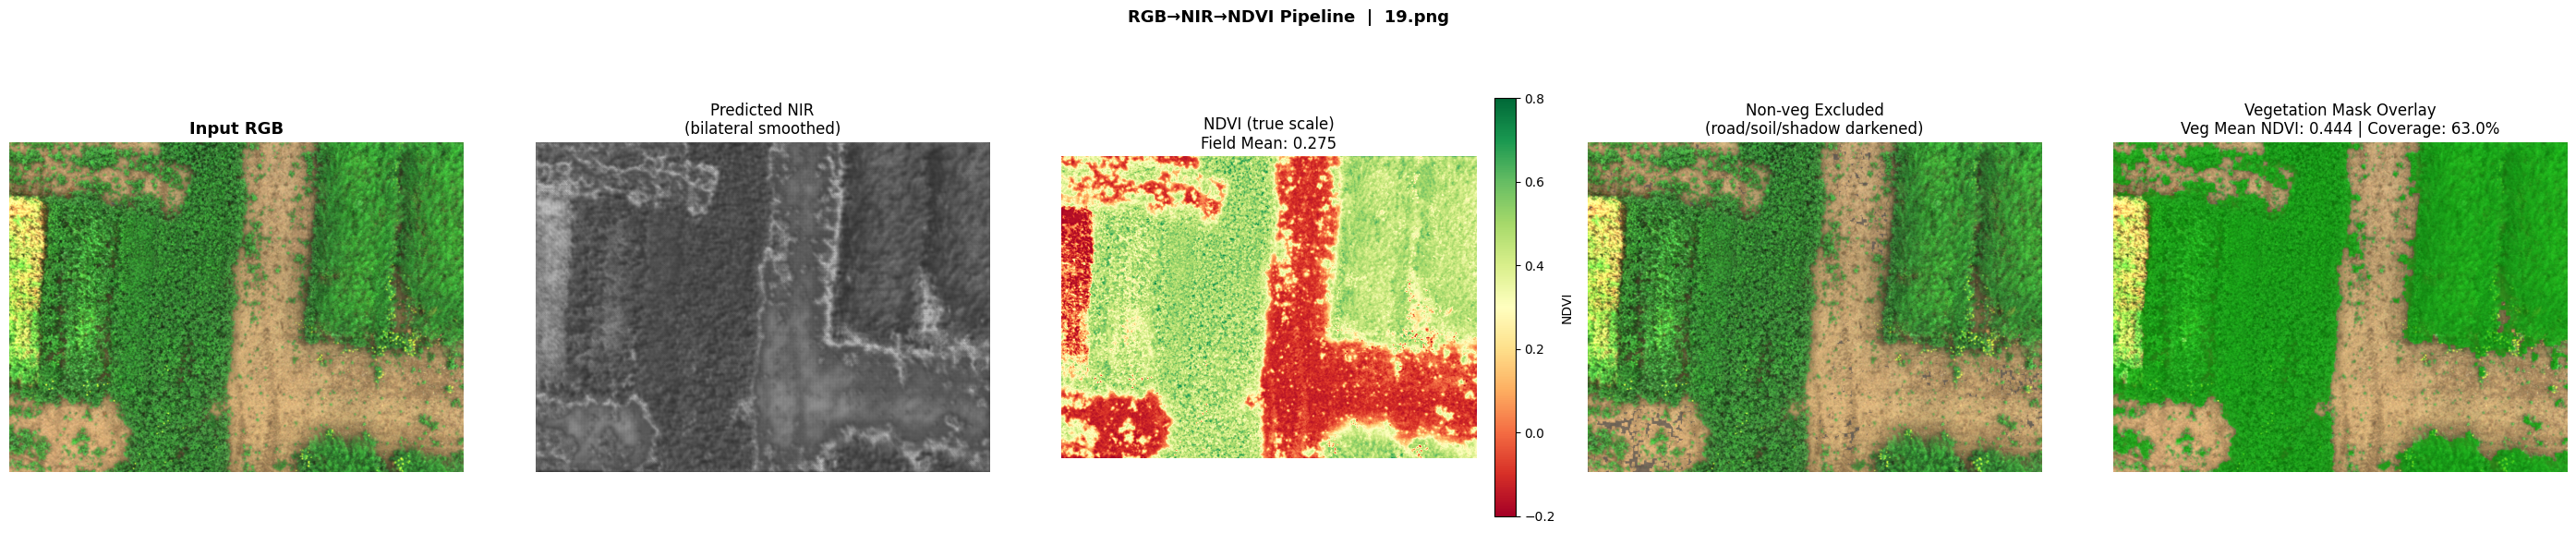

  Saved            → /kaggle/working/improved_inference_results/19
  Field Mean NDVI  : 0.275  (roads/soil excluded)
  Vegetation NDVI  : 0.444
  Veg Coverage     : 63.0%  (of field area)



{'ndvi_field_mean': 0.2749146819114685,
 'ndvi_veg_mean': 0.4442620575428009,
 'coverage_pct': 62.962054831277705}

In [31]:
# ============================================================
# IMPROVED INFERENCE SCRIPT v3 - Fixed Artifacts + Better Masking
# ============================================================
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import os

# ====================== SETTINGS ======================
MODEL_PATH = "/kaggle/input/models/chitranshdamedhar/finetunedmodel-40-epoch/pytorch/default/1/finetuned_epoch40.pth"
OUTPUT_DIR = "/kaggle/working/improved_inference_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ====================== MODEL ======================
class EfficientUNetGenerator(nn.Module):
    def __init__(self, base_channels=40):
        super().__init__()
        bc = base_channels
        self.enc1 = self._down_block(3, bc)
        self.enc2 = self._down_block(bc, bc*2)
        self.enc3 = self._down_block(bc*2, bc*4)
        self.bottleneck = nn.Sequential(
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4), nn.ReLU(inplace=True),
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4), nn.ReLU(inplace=True),
        )
        self.up3  = nn.ConvTranspose2d(bc*4, bc*2, 4, 2, 1)
        self.dec3 = self._up_block(bc*4, bc*2)
        self.up2  = nn.ConvTranspose2d(bc*2, bc, 4, 2, 1)
        self.dec2 = self._up_block(bc*2, bc)
        self.final = nn.Sequential(
            nn.ConvTranspose2d(bc, bc//2, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc//2, 1, 3, padding=1),
            nn.Tanh()
        )

    def _down_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.LeakyReLU(0.2, inplace=True),
        )

    def _up_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        b  = self.bottleneck(e3)
        d3 = self.dec3(torch.cat([self.up3(b), e2], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e1], 1))
        return self.final(d2)

G = EfficientUNetGenerator(base_channels=40).to(DEVICE)
G.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
G.eval()
print(f"✅ Model loaded on {DEVICE}\n")

# ====================== TILED INFERENCE (Fixed) ======================
def tiled_predict(rgb_np, tile_size=256, overlap=128):
    """
    overlap=128 (50%) gives much smoother blending than overlap=64.
    Gaussian window ensures tile centers dominate — edges are heavily discounted.
    """
    h, w = rgb_np.shape[:2]
    nir_acc    = np.zeros((h, w), dtype=np.float64)
    weight_acc = np.zeros((h, w), dtype=np.float64)

    step = tile_size - overlap

    # Build Gaussian window once
    k   = cv2.getGaussianKernel(tile_size, tile_size / 5)
    win = (k @ k.T).astype(np.float64)
    # Normalize so peak = 1
    win /= win.max()

    tile_tf = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

    ys = list(range(0, max(1, h - tile_size), step)) + [max(0, h - tile_size)]
    xs = list(range(0, max(1, w - tile_size), step)) + [max(0, w - tile_size)]
    ys = sorted(set(ys))
    xs = sorted(set(xs))

    with torch.no_grad():
        for y in ys:
            for x in xs:
                y2, x2 = min(y + tile_size, h), min(x + tile_size, w)
                tile = rgb_np[y:y2, x:x2]
                th, tw = tile.shape[:2]
                if th < 16 or tw < 16:
                    continue
                # Pad if smaller than tile_size (edge tiles)
                padded = np.zeros((tile_size, tile_size, 3), dtype=rgb_np.dtype)
                padded[:th, :tw] = tile
                inp = tile_tf(Image.fromarray(padded)).unsqueeze(0).to(DEVICE)
                pred_nir = (G(inp) * 0.5 + 0.5).clamp(0, 1).squeeze().cpu().numpy()
                # Only accumulate the valid (non-padded) region
                nir_acc[y:y2, x:x2]    += pred_nir[:th, :tw] * win[:th, :tw]
                weight_acc[y:y2, x:x2] += win[:th, :tw]

    weight_acc = np.where(weight_acc < 1e-8, 1e-8, weight_acc)
    result = (nir_acc / weight_acc).astype(np.float32)

    # Post-process: bilateral filter to smooth tile seams while preserving edges
    result_u8  = (result * 255).clip(0, 255).astype(np.uint8)
    result_u8  = cv2.bilateralFilter(result_u8, d=9, sigmaColor=25, sigmaSpace=25)
    return result_u8.astype(np.float32) / 255.0


# ====================== SOIL / ROAD EXCLUSION MASK ======================
def get_non_vegetation_mask(rgb_np):
    """
    Returns a binary mask where True = likely soil, road, or shadow.
    Uses ExG (Excess Green) + HSV saturation + brightness.
    These pixels will be excluded from NDVI stats.
    """
    img_f  = rgb_np.astype(np.float32) / 255.0
    R, G, B = img_f[:,:,0], img_f[:,:,1], img_f[:,:,2]

    # Excess Green Index — vegetation tends to be positive
    ExG = 2*G - R - B

    # HSV for saturation and value
    hsv = cv2.cvtColor(rgb_np, cv2.COLOR_RGB2HSV).astype(np.float32)
    sat = hsv[:,:,1] / 255.0
    val = hsv[:,:,2] / 255.0

    # Road/path: low saturation, mid-high brightness, brownish-grey
    is_road   = (sat < 0.15) & (val > 0.25)
    # Shadow: very dark
    is_shadow = val < 0.12
    # Bare soil: brown hue range (10-30 deg HSV), low ExG
    hue = hsv[:,:,0]
    is_soil   = ((hue > 8) & (hue < 32)) & (ExG < 0.0) & (sat > 0.1)

    non_veg_mask = is_road | is_shadow | is_soil
    # Clean up with morphological ops
    non_veg_mask = cv2.morphologyEx(
        non_veg_mask.astype(np.uint8),
        cv2.MORPH_CLOSE,
        np.ones((7, 7), np.uint8)
    ).astype(bool)
    return non_veg_mask


# ====================== MAIN INFERENCE ======================
def improved_test(rgb_path, ndvi_veg_threshold=0.25):
    print(f"Processing: {os.path.basename(rgb_path)}")
    rgb_pil  = Image.open(rgb_path).convert('RGB')
    original = np.array(rgb_pil)
    h, w     = original.shape[:2]

    # ── NIR Prediction ──────────────────────────────────────────────
    print("  → Tiled inference (overlap=128, bilateral smoothing)...")
    pred_nir = tiled_predict(original, tile_size=256, overlap=128)
    if pred_nir.shape != (h, w):
        pred_nir = cv2.resize(pred_nir, (w, h), interpolation=cv2.INTER_LINEAR)

    # ── NDVI (correct channel) ───────────────────────────────────────
    red  = original[:, :, 0].astype(np.float32) / 255.0   # index 0 = R
    ndvi = (pred_nir - red) / (pred_nir + red + 1e-6)
    ndvi = np.clip(ndvi, -1.0, 1.0)

    # ── Non-vegetation exclusion ─────────────────────────────────────
    non_veg = get_non_vegetation_mask(original)

    # ── Vegetation mask: NDVI threshold + exclude non-veg ───────────
    veg_mask_raw = (ndvi > ndvi_veg_threshold) & (~non_veg)
    # Clean small blobs
    veg_mask_u8  = cv2.morphologyEx(
        veg_mask_raw.astype(np.uint8) * 255,
        cv2.MORPH_OPEN,
        np.ones((5, 5), np.uint8)
    )
    # Fill small holes inside vegetation regions
    veg_mask_u8  = cv2.morphologyEx(
        veg_mask_u8,
        cv2.MORPH_CLOSE,
        np.ones((9, 9), np.uint8)
    )
    veg_mask = veg_mask_u8 > 128

    # ── Stats (exclude non-veg from overall mean too) ────────────────
    valid_pixels     = ndvi[~non_veg]
    veg_pixels       = ndvi[veg_mask]
    overall_mean     = float(np.mean(valid_pixels)) if len(valid_pixels) > 0 else 0.0
    mean_veg_ndvi    = float(np.mean(veg_pixels))   if len(veg_pixels)   > 0 else 0.0
    coverage_pct     = np.sum(veg_mask) / (~non_veg).sum() * 100  # % of field area, not whole image

    # ── Visualize NDVI on actual -1 to 1 scale ───────────────────────
    # Custom colormap: red (low/stressed) → yellow → green (healthy)
    ndvi_cmap = plt.cm.RdYlGn

    # ── Save outputs ─────────────────────────────────────────────────
    base_name = os.path.splitext(os.path.basename(rgb_path))[0]
    save_dir  = f"{OUTPUT_DIR}/{base_name}"
    os.makedirs(save_dir, exist_ok=True)

    np.save(f"{save_dir}/ndvi_raw.npy", ndvi)   # save float NDVI for further analysis
    cv2.imwrite(f"{save_dir}/RGB.jpg",           cv2.cvtColor(original, cv2.COLOR_RGB2BGR))
    cv2.imwrite(f"{save_dir}/Predicted_NIR.png", (pred_nir * 255).astype(np.uint8))
    cv2.imwrite(f"{save_dir}/Mask.png",          veg_mask_u8)

    # ── Professional 5-panel figure ──────────────────────────────────
    fig, axs = plt.subplots(1, 5, figsize=(28, 6))

    axs[0].imshow(original)
    axs[0].set_title("Input RGB", fontsize=13, fontweight='bold')
    axs[0].axis('off')

    axs[1].imshow(pred_nir, cmap='gray')
    axs[1].set_title("Predicted NIR\n(bilateral smoothed)", fontsize=12)
    axs[1].axis('off')

    # NDVI on true scale with proper colorbar
    im2 = axs[2].imshow(ndvi, cmap=ndvi_cmap, vmin=-0.2, vmax=0.8)
    axs[2].set_title(f"NDVI (true scale)\nField Mean: {overall_mean:.3f}", fontsize=12)
    axs[2].axis('off')
    plt.colorbar(im2, ax=axs[2], fraction=0.046, pad=0.04, label='NDVI')

    # Non-veg exclusion overlay
    exclusion_vis = original.copy()
    exclusion_vis[non_veg] = (exclusion_vis[non_veg] * 0.3 + np.array([80, 80, 80]) * 0.7).clip(0, 255).astype(np.uint8)
    axs[3].imshow(exclusion_vis)
    axs[3].set_title("Non-veg Excluded\n(road/soil/shadow darkened)", fontsize=12)
    axs[3].axis('off')

    # Vegetation mask overlaid on RGB
    overlay = original.copy()
    green_tint             = np.zeros_like(original)
    green_tint[:,:,1]      = 180
    overlay[veg_mask]      = (original[veg_mask] * 0.5 + green_tint[veg_mask] * 0.5).astype(np.uint8)
    axs[4].imshow(overlay)
    axs[4].set_title(
        f"Vegetation Mask Overlay\nVeg Mean NDVI: {mean_veg_ndvi:.3f} | Coverage: {coverage_pct:.1f}%",
        fontsize=12
    )
    axs[4].axis('off')

    plt.suptitle(f"RGB→NIR→NDVI Pipeline  |  {os.path.basename(rgb_path)}", fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(f"{save_dir}/Final_Result.jpg", dpi=220, bbox_inches='tight')
    plt.show()

    print(f"  Saved            → {save_dir}")
    print(f"  Field Mean NDVI  : {overall_mean:.3f}  (roads/soil excluded)")
    print(f"  Vegetation NDVI  : {mean_veg_ndvi:.3f}")
    print(f"  Veg Coverage     : {coverage_pct:.1f}%  (of field area)\n")

    return {
        "ndvi_field_mean": overall_mean,
        "ndvi_veg_mean":   mean_veg_ndvi,
        "coverage_pct":    coverage_pct,
    }


# ====================== RUN ======================
your_image = "/kaggle/input/rgbnir-aerial-crop-dataset/Canola dataset/Canola dataset/canola_06082019/RGB/19.png"
improved_test(your_image, ndvi_veg_threshold=0.25)

✅ Model loaded successfully!



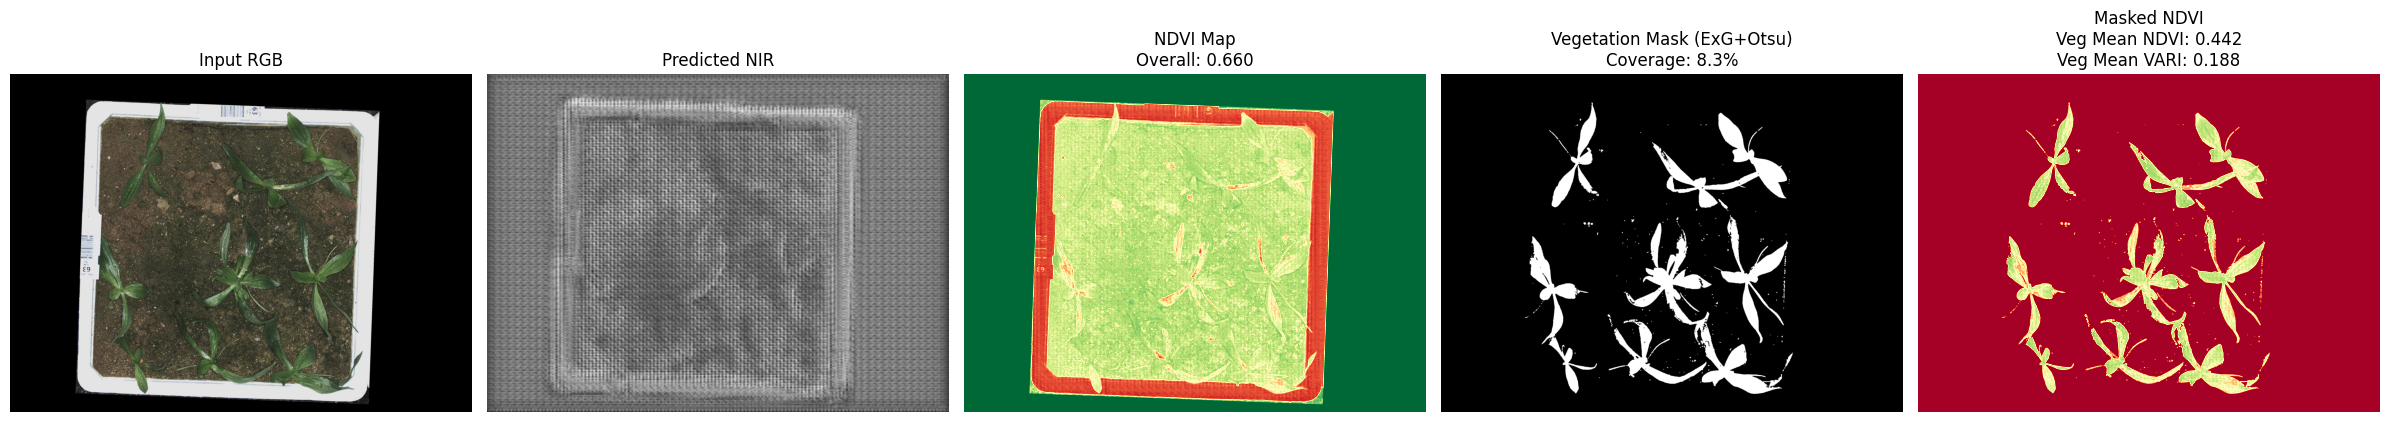

Overall Mean NDVI     : 0.660
Vegetation-only NDVI  : 0.442
Vegetation-only VARI  : 0.188
Vegetation Coverage   : 8.3%


In [25]:
# ============================================================
# UPDATED INFERENCE SCRIPT – Robust Vegetation Segmentation (ExG)     11:00pm 22/4/26
# ============================================================
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

# ====================== SETTINGS ======================
MODEL_PATH = "/kaggle/input/models/chitranshdamedhar/finetunedmodel-40-epoch/pytorch/default/1/finetuned_epoch40.pth"
OUTPUT_DIR = "/kaggle/working/manual_test"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ====================== GENERATOR MODEL ======================
class EfficientUNetGenerator(nn.Module):
    def __init__(self, base_channels=40):
        super().__init__()
        bc = base_channels
        
        self.enc1 = self._down_block(3, bc)
        self.enc2 = self._down_block(bc, bc*2)
        self.enc3 = self._down_block(bc*2, bc*4)
        
        self.bottleneck = nn.Sequential(
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4), nn.ReLU(inplace=True),
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4), nn.ReLU(inplace=True),
        )
        
        self.up3 = nn.ConvTranspose2d(bc*4, bc*2, 4, 2, 1)
        self.dec3 = self._up_block(bc*4, bc*2)
        
        self.up2 = nn.ConvTranspose2d(bc*2, bc, 4, 2, 1)
        self.dec2 = self._up_block(bc*2, bc)
        
        self.final = nn.Sequential(
            nn.ConvTranspose2d(bc, bc//2, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc//2, 1, 3, padding=1),
            nn.Tanh()
        )

    def _down_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True),
        )

    def _up_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        b = self.bottleneck(e3)
        d3 = torch.cat([self.up3(b), e2], dim=1)
        d3 = self.dec3(d3)
        d2 = torch.cat([self.up2(d3), e1], dim=1)
        d2 = self.dec2(d2)
        return self.final(d2)

# ====================== LOAD MODEL ======================
G = EfficientUNetGenerator(base_channels=40).to(DEVICE)
G.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
G.eval()
print("✅ Model loaded successfully!\n")

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# ====================== VEGETATION SEGMENTATION (ExG) ======================
def create_vegetation_mask(rgb_image):
    """
    Compute Excess Green (ExG) index and threshold to obtain vegetation mask.
    Args:
        rgb_image: numpy array (H, W, 3) uint8
    Returns:
        mask: boolean array (H, W) where True = vegetation
    """
    img_float = rgb_image.astype(np.float32) / 255.0
    R = img_float[:, :, 0]
    G = img_float[:, :, 1]
    B = img_float[:, :, 2]
    
    ExG = 2 * G - R - B
    exg_vis = cv2.normalize(ExG, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)
    _, mask_otsu = cv2.threshold(exg_vis, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    kernel = np.ones((5, 5), np.uint8)
    mask_clean = cv2.morphologyEx(mask_otsu, cv2.MORPH_CLOSE, kernel)
    mask_clean = cv2.morphologyEx(mask_clean, cv2.MORPH_OPEN, kernel)
    
    return mask_clean > 0

# ====================== RGB INDICES ======================
def compute_rgb_indices(rgb_image):
    img = rgb_image.astype(np.float32) / 255.0
    R, G, B = img[:,:,0], img[:,:,1], img[:,:,2]
    eps = 1e-8
    return {
        'VARI': (G - R) / (G + R - B + eps),
        'GLI': (2*G - R - B) / (2*G + R + B + eps),
        'ExG': 2*G - R - B,
        'RGBVI': (G**2 - B*R) / (G**2 + B*R + eps)
    }

# ====================== TEST FUNCTION ======================
def test_image(image_path):
    rgb_pil = Image.open(image_path).convert('RGB')
    original = np.array(rgb_pil)
    h, w = original.shape[:2]
    
    # Predict NIR
    input_tensor = transform(rgb_pil).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = G(input_tensor)
        pred_nir = (pred * 0.5 + 0.5).clamp(0, 1).squeeze().cpu().numpy()
    pred_nir = cv2.resize(pred_nir, (w, h))
    
    # NDVI
    red = original[:, :, 2].astype(np.float32) / 255.0
    ndvi = (pred_nir - red) / (pred_nir + red + 1e-6)
    ndvi = np.clip(ndvi, -1.0, 1.0)
    
    # Vegetation mask
    veg_mask = create_vegetation_mask(original)
    
    # Stats
    veg_ndvi_values = ndvi[veg_mask]
    veg_ndvi_mean = np.mean(veg_ndvi_values) if veg_ndvi_values.size > 0 else 0.0
    coverage = 100 * np.sum(veg_mask) / veg_mask.size
    
    # RGB index for comparison
    indices = compute_rgb_indices(original)
    vari = indices['VARI']
    vari_veg_mean = np.mean(vari[veg_mask]) if veg_ndvi_values.size > 0 else 0.0
    
    # Visualization
    ndvi_vis = cv2.normalize(ndvi, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)
    ndvi_masked = np.where(veg_mask, ndvi_vis, 0)
    
    fig, axs = plt.subplots(1, 5, figsize=(24, 5))
    
    axs[0].imshow(original)
    axs[0].set_title("Input RGB")
    axs[0].axis('off')
    
    axs[1].imshow(pred_nir, cmap='gray')
    axs[1].set_title("Predicted NIR")
    axs[1].axis('off')
    
    axs[2].imshow(ndvi_vis, cmap='RdYlGn')
    axs[2].set_title(f"NDVI Map\nOverall: {np.mean(ndvi):.3f}")
    axs[2].axis('off')
    
    axs[3].imshow(veg_mask, cmap='gray')
    axs[3].set_title(f"Vegetation Mask (ExG+Otsu)\nCoverage: {coverage:.1f}%")
    axs[3].axis('off')
    
    axs[4].imshow(ndvi_masked, cmap='RdYlGn')
    axs[4].set_title(f"Masked NDVI\nVeg Mean NDVI: {veg_ndvi_mean:.3f}\nVeg Mean VARI: {vari_veg_mean:.3f}")
    axs[4].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print(f"Overall Mean NDVI     : {np.mean(ndvi):.3f}")
    print(f"Vegetation-only NDVI  : {veg_ndvi_mean:.3f}")
    print(f"Vegetation-only VARI  : {vari_veg_mean:.3f}")
    print(f"Vegetation Coverage   : {coverage:.1f}%")

# ====================== RUN ======================
image_path = "/kaggle/input/datasets/chitranshdamedhar/test-img111/closeup.jpg"
test_image(image_path)

In [1]:
import os
!git clone --depth 1 https://github.com/mamta-joshi-gehlot/Tomato-Village.git

!mkdir -p /kaggle/working/tomato_train_images
!cp -r "Tomato-Village/Variant-c(Object Detection)/train/images" /kaggle/working/tomato_train_images/

print("✅ Done! Images are in /kaggle/working/tomato_train_images/images")

Cloning into 'Tomato-Village'...
remote: Enumerating objects: 45017, done.
remote: Counting objects: 100% (45017/45017), done.
remote: Compressing objects: 100% (30366/30366), done.
remote: Total 45017 (delta 14369), reused 44968 (delta 14325), pack-reused 0 (from 0)
Receiving objects: 100% (45017/45017), 3.15 GiB | 55.58 MiB/s, done.
Resolving deltas: 100% (14369/14369), done.
Updating files: 100% (53289/53289), done.
✅ Done! Images are in /kaggle/working/tomato_train_images/images


In [8]:
# ============================================================
# IMPROVED INFERENCE with Lightning Normalization
# ============================================================
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
import glob
import random

# ====================== SETTINGS ======================
MODEL_PATH = "/kaggle/input/models/chitranshdamedhar/finetunedmodel-40-epoch/pytorch/default/1/finetuned_epoch40.pth"
DATASET_IMAGES_DIR = "/kaggle/working/tomato_train_images/images"
OUTPUT_DIR = "/kaggle/working/normalized"
NUM_IMAGES_TO_TEST = 8

os.makedirs(OUTPUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ====================== MODEL (same) ======================
class EfficientUNetGenerator(nn.Module):
    def __init__(self, base_channels=40):
        super().__init__()
        bc = base_channels
        self.enc1 = self._down_block(3, bc)
        self.enc2 = self._down_block(bc, bc*2)
        self.enc3 = self._down_block(bc*2, bc*4)
        
        self.bottleneck = nn.Sequential(
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4), nn.ReLU(inplace=True),
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4), nn.ReLU(inplace=True),
        )
        
        self.up3 = nn.ConvTranspose2d(bc*4, bc*2, 4, 2, 1)
        self.dec3 = self._up_block(bc*4, bc*2)
        self.up2 = nn.ConvTranspose2d(bc*2, bc, 4, 2, 1)
        self.dec2 = self._up_block(bc*2, bc)
        
        self.final = nn.Sequential(
            nn.ConvTranspose2d(bc, bc//2, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc//2, 1, 3, padding=1),
            nn.Tanh()
        )

    def _down_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True),
        )

    def _up_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        b = self.bottleneck(e3)
        d3 = torch.cat([self.up3(b), e2], 1)
        d3 = self.dec3(d3)
        d2 = torch.cat([self.up2(d3), e1], 1)
        d2 = self.dec2(d2)
        return self.final(d2)


G = EfficientUNetGenerator(base_channels=40).to(DEVICE)
G.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
G.eval()

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# ====================== LIGHTNING NORMALIZATION ======================
def normalize_lighting(rgb_image):
    """Adaptive lighting normalization to handle too bright / too dark images"""
    lab = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    
    # CLAHE on L channel (good for over-exposed images)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    l_clahe = clahe.apply(l)
    
    lab_clahe = cv2.merge((l_clahe, a, b))
    rgb_normalized = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)
    return rgb_normalized

# ====================== TEST FUNCTION ======================
def test_image(image_path, save_name):
    rgb_pil = Image.open(image_path).convert('RGB')
    original = np.array(rgb_pil)
    
    # Apply lighting normalization
    normalized_rgb = normalize_lighting(original)
    
    # Predict NIR
    input_tensor = transform(Image.fromarray(normalized_rgb)).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = G(input_tensor)
        pred_nir = (pred * 0.5 + 0.5).clamp(0, 1).squeeze().cpu().numpy()
    
    h, w = original.shape[:2]
    pred_nir = cv2.resize(pred_nir, (w, h))
    
    red = original[:, :, 2].astype(np.float32) / 255.0
    ndvi = (pred_nir - red) / (pred_nir + red + 1e-6)
    ndvi = np.clip(ndvi, -1.0, 1.0)
    
    ndvi_vis = cv2.normalize(ndvi, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)
    _, mask = cv2.threshold(ndvi_vis, 105, 255, cv2.THRESH_BINARY)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5,5), np.uint8))
    
    # Vegetation-only NDVI
    veg_ndvi = np.mean(ndvi[mask > 128]) if np.any(mask > 128) else 0.0
    
    # Save summary
    fig, axs = plt.subplots(1, 4, figsize=(20, 5))
    axs[0].imshow(original)
    axs[0].set_title("Input RGB (Original)")
    axs[0].axis('off')
    
    axs[1].imshow(pred_nir, cmap='gray')
    axs[1].set_title("Predicted NIR")
    axs[1].axis('off')
    
    axs[2].imshow(ndvi_vis, cmap='RdYlGn')
    axs[2].set_title(f"NDVI Map\nOverall: {np.mean(ndvi):.3f}\nVeg: {veg_ndvi:.3f}")
    axs[2].axis('off')
    
    axs[3].imshow(mask, cmap='gray')
    axs[3].set_title(f"Mask\nCoverage: {(np.sum(mask>128)/mask.size*100):.1f}%")
    axs[3].axis('off')
    
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/{save_name}_result.jpg", dpi=200, bbox_inches='tight')
    plt.close()
    
    print(f"Saved: {save_name} | Overall NDVI: {np.mean(ndvi):.3f} | Veg NDVI: {veg_ndvi:.3f} | Coverage: {(np.sum(mask>128)/mask.size*100):.1f}%")

# ====================== RUN ======================
random.seed(42)
image_files = glob.glob(f"{DATASET_IMAGES_DIR}/*.jpg") + glob.glob(f"{DATASET_IMAGES_DIR}/*.png")

if not image_files:
    print("No images found!")
else:
    selected = random.sample(image_files, min(NUM_IMAGES_TO_TEST, len(image_files)))
    
    for idx, path in enumerate(selected):
        base_name = os.path.splitext(os.path.basename(path))[0]
        test_image(path, f"test_{idx:02d}_{base_name}")

print(f"\n✅ All results saved in: {OUTPUT_DIR}")

Saved: test_00_IMG20220324085256_aug4 | Overall NDVI: 0.323 | Veg NDVI: 0.498 | Coverage: 47.8%
Saved: test_01_IMG20220325092501_aug1 | Overall NDVI: 0.385 | Veg NDVI: 0.603 | Coverage: 54.0%
Saved: test_02_Jaipur_Pots (589)_aug4 | Overall NDVI: 0.262 | Veg NDVI: 0.508 | Coverage: 45.5%
Saved: test_03_IMG20220324085557_aug1 | Overall NDVI: 0.567 | Veg NDVI: 0.668 | Coverage: 78.6%
Saved: test_04_Jaipur_Pots (617)_aug3 | Overall NDVI: 0.295 | Veg NDVI: 0.427 | Coverage: 63.1%
Saved: test_05_IMG20220324093802_aug3 | Overall NDVI: 0.301 | Veg NDVI: 0.549 | Coverage: 42.4%
Saved: test_06_IMG20220323084913_aug4 | Overall NDVI: 0.319 | Veg NDVI: 0.470 | Coverage: 49.7%
Saved: test_07_IMG20220323085214_aug7 | Overall NDVI: 0.314 | Veg NDVI: 0.540 | Coverage: 39.9%

✅ All results saved in: /kaggle/working/normalized_lightning


In [10]:
# ============================================================
# CORRECTED TRAINING SCRIPT – SHARP NIR GENERATION
# Fixes: Blur (L1 weight), Grain (strong D), Detail (Perceptual)
# ============================================================
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision.transforms import functional as TF
from torchvision import models
from PIL import Image
from tqdm import tqdm
import glob
import random
import numpy as np

# --------------------- Settings ---------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

BATCH_SIZE = 8
EPOCHS = 60
LR_G = 0.0002
LR_D = 0.0001
IMAGE_SIZE = 256

LAMBDA_L1 = 20.0        # Reduced from 150
LAMBDA_PERC = 10.0      # Perceptual loss weight
LAMBDA_GAN = 1.0
LAMBDA_NDVI = 2.0

CHECKPOINT_PATH = "/kaggle/working/rgb2nir_generator_epoch60.pth"

# --------------------- Dataset (unchanged) ---------------------
PAIRED_DIR = "/kaggle/working/pix2pix_rgb2nir/pytorch-CycleGAN-and-pix2pix/datasets/rgb2nir/train"
image_paths = sorted(glob.glob(f"{PAIRED_DIR}/*.png") + glob.glob(f"{PAIRED_DIR}/*.jpg"))
print(f"Found {len(image_paths)} paired images.")

class PairedDataset(Dataset):
    def __init__(self, image_paths):
        self.image_paths = image_paths
        self.transform = transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('RGB')
        w = img.width // 2
        rgb = img.crop((0, 0, w, img.height))
        nir = img.crop((w, 0, img.width, img.height))
        rgb = self.transform(rgb)
        nir = transforms.Grayscale()(self.transform(nir))
        if random.random() > 0.5:
            rgb = TF.hflip(rgb)
            nir = TF.hflip(nir)
        return rgb, nir

dataset = PairedDataset(image_paths)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=2, pin_memory=True, drop_last=True)
print(f"✅ Dataloader ready with {len(dataset)} images")

# --------------------- Improved Generator (base_channels=64) ---------------------
class UNetGenerator(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base_ch=64):
        super().__init__()
        # Encoder
        self.enc1 = self._conv_block(in_ch, base_ch)
        self.enc2 = self._conv_block(base_ch, base_ch*2)
        self.enc3 = self._conv_block(base_ch*2, base_ch*4)
        self.enc4 = self._conv_block(base_ch*4, base_ch*8)
        
        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(base_ch*8, base_ch*8, 3, padding=1),
            nn.BatchNorm2d(base_ch*8),
            nn.ReLU(inplace=True),
            nn.Conv2d(base_ch*8, base_ch*8, 3, padding=1),
            nn.BatchNorm2d(base_ch*8),
            nn.ReLU(inplace=True)
        )
        
        # Decoder (upsampling + conv blocks)
        self.up4 = nn.ConvTranspose2d(base_ch*8, base_ch*4, 4, 2, 1)
        self.dec4 = self._conv_block(base_ch*8, base_ch*4, use_upsample=False)  # note: in_ch = base_ch*4 (from up4) + base_ch*4 (skip) = base_ch*8
        
        self.up3 = nn.ConvTranspose2d(base_ch*4, base_ch*2, 4, 2, 1)
        self.dec3 = self._conv_block(base_ch*4, base_ch*2, use_upsample=False)
        
        self.up2 = nn.ConvTranspose2d(base_ch*2, base_ch, 4, 2, 1)
        self.dec2 = self._conv_block(base_ch*2, base_ch, use_upsample=False)
        
        self.final = nn.Sequential(
            nn.ConvTranspose2d(base_ch, base_ch//2, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(base_ch//2, out_ch, 3, padding=1),
            nn.Tanh()
        )

    def _conv_block(self, in_ch, out_ch, use_upsample=True):
        """If use_upsample=False, this block is for decoder after concatenation."""
        layers = [
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        ]
        if use_upsample:
            # Encoder uses stride 2 downsampling
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 4, 2, 1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.LeakyReLU(0.2, inplace=True)
            )
        else:
            # Decoder block (no downsampling, just conv+bn+relu)
            return nn.Sequential(*layers)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)          # [B, 64, 128, 128]
        e2 = self.enc2(e1)         # [B, 128, 64, 64]
        e3 = self.enc3(e2)         # [B, 256, 32, 32]
        e4 = self.enc4(e3)         # [B, 512, 16, 16]
        
        # Bottleneck
        b = self.bottleneck(e4)    # [B, 512, 16, 16]
        
        # Decoder with skip connections
        d4 = self.up4(b)           # [B, 256, 32, 32]
        d4 = torch.cat([d4, e3], dim=1)  # [B, 512, 32, 32] (256+256)
        d4 = self.dec4(d4)         # [B, 256, 32, 32]
        
        d3 = self.up3(d4)          # [B, 128, 64, 64]
        d3 = torch.cat([d3, e2], dim=1)  # [B, 256, 64, 64]
        d3 = self.dec3(d3)         # [B, 128, 64, 64]
        
        d2 = self.up2(d3)          # [B, 64, 128, 128]
        d2 = torch.cat([d2, e1], dim=1)  # [B, 128, 128, 128]
        d2 = self.dec2(d2)         # [B, 64, 128, 128]
        
        out = self.final(d2)       # [B, 1, 256, 256]
        return out
# --------------------- Perceptual Loss (VGG16) ---------------------
class PerceptualLoss(nn.Module):
    def __init__(self):
        super().__init__()
        vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features[:16].eval()
        for param in vgg.parameters():
            param.requires_grad = False
        self.vgg = vgg.to(DEVICE)
        self.criterion = nn.L1Loss()

    def forward(self, fake, real):
        # Convert from [-1,1] to [0,1]
        fake = (fake + 1) / 2
        real = (real + 1) / 2
        # Repeat single channel to 3 channels for VGG
        fake_rgb = fake.repeat(1, 3, 1, 1)
        real_rgb = real.repeat(1, 3, 1, 1)
        fake_feat = self.vgg(fake_rgb)
        real_feat = self.vgg(real_rgb)
        return self.criterion(fake_feat, real_feat)

# --------------------- Stronger Discriminator (Spectral Norm) ---------------------
class NLayerDiscriminator(nn.Module):
    def __init__(self, in_ch=4, ndf=64, n_layers=4):
        super().__init__()
        layers = [
            nn.utils.spectral_norm(nn.Conv2d(in_ch, ndf, 4, 2, 1)),
            nn.LeakyReLU(0.2, inplace=True)
        ]
        nf_mult = 1
        for n in range(1, n_layers):
            nf_mult_prev = nf_mult
            nf_mult = min(2**n, 8)
            layers += [
                nn.utils.spectral_norm(nn.Conv2d(ndf * nf_mult_prev, ndf * nf_mult, 4, 2, 1, bias=False)),
                nn.BatchNorm2d(ndf * nf_mult),
                nn.LeakyReLU(0.2, inplace=True)
            ]
        nf_mult_prev = nf_mult
        nf_mult = min(2**n_layers, 8)
        layers += [
            nn.utils.spectral_norm(nn.Conv2d(ndf * nf_mult_prev, ndf * nf_mult, 4, 1, 1, bias=False)),
            nn.BatchNorm2d(ndf * nf_mult),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * nf_mult, 1, 4, 1, 1)
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

# --------------------- Vegetation-Masked NDVI Loss ---------------------
def masked_ndvi_loss(fake_nir, rgb):
    """
    Compute NDVI only on vegetation pixels (ExG > 0.1)
    """
    red = rgb[:, 0:1, :, :]
    green = rgb[:, 1:2, :, :]
    blue = rgb[:, 2:3, :, :]
    # Convert from [-1,1] to [0,1] for ExG calculation
    red_01 = (red + 1) / 2
    green_01 = (green + 1) / 2
    blue_01 = (blue + 1) / 2
    exg = 2 * green_01 - red_01 - blue_01
    veg_mask = (exg > 0.1).float()

    # Compute NDVI (fake_nir is in [-1,1], convert red to same)
    nir_01 = (fake_nir + 1) / 2
    red_01_norm = (red + 1) / 2  # already in [0,1]
    ndvi_pred = (nir_01 - red_01_norm) / (nir_01 + red_01_norm + 1e-6)
    ndvi_target = torch.clamp(ndvi_pred, -0.2, 0.9)

    loss = nn.L1Loss(reduction='none')(ndvi_pred, ndvi_target)
    masked_loss = (loss * veg_mask).sum() / (veg_mask.sum() + 1e-6)
    return masked_loss

# --------------------- Initialize Models ---------------------
G = UNetGenerator(in_ch=3, out_ch=1, base_ch=64).to(DEVICE)
D = NLayerDiscriminator(in_ch=4, ndf=64, n_layers=4).to(DEVICE)
perceptual_loss = PerceptualLoss()

if os.path.exists(CHECKPOINT_PATH):
    G.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE))
    print(f"✅ Loaded checkpoint: {CHECKPOINT_PATH}")
else:
    print("⚠️ No checkpoint found. Training from scratch.")

# --------------------- Optimizers & Schedulers ---------------------
optimizer_G = optim.Adam(G.parameters(), lr=LR_G, betas=(0.5, 0.999))
optimizer_D = optim.Adam(D.parameters(), lr=LR_D, betas=(0.5, 0.999))
scheduler_G = optim.lr_scheduler.StepLR(optimizer_G, step_size=30, gamma=0.5)
scheduler_D = optim.lr_scheduler.StepLR(optimizer_D, step_size=30, gamma=0.5)

criterion_GAN = nn.MSELoss()  # LSGAN loss

# --------------------- Training Loop ---------------------
print("\n🚀 Starting training...\n")
for epoch in range(EPOCHS):
    G.train()
    D.train()
    total_g_loss = 0.0
    total_d_loss = 0.0

    pbar = tqdm(dataloader, desc=f"Epoch {epoch+1}/{EPOCHS}")
    for rgb, nir in pbar:
        rgb = rgb.to(DEVICE)
        nir = nir.to(DEVICE)
        batch_size = rgb.size(0)

        # ---------- Train Discriminator ----------
        optimizer_D.zero_grad()
        fake_nir = G(rgb).detach()
        real_pair = torch.cat([rgb, nir], dim=1)
        fake_pair = torch.cat([rgb, fake_nir], dim=1)

        pred_real = D(real_pair)
        pred_fake = D(fake_pair)

        loss_D_real = criterion_GAN(pred_real, torch.ones_like(pred_real))
        loss_D_fake = criterion_GAN(pred_fake, torch.zeros_like(pred_fake))
        loss_D = (loss_D_real + loss_D_fake) * 0.5
        loss_D.backward()
        optimizer_D.step()

        # ---------- Train Generator ----------
        optimizer_G.zero_grad()
        fake_nir = G(rgb)
        fake_pair = torch.cat([rgb, fake_nir], dim=1)
        pred_fake = D(fake_pair)

        loss_G_GAN = criterion_GAN(pred_fake, torch.ones_like(pred_fake))
        loss_G_L1 = nn.L1Loss()(fake_nir, nir)
        loss_G_Perc = perceptual_loss(fake_nir, nir)
        loss_G_NDVI = masked_ndvi_loss(fake_nir, rgb)

        loss_G = (LAMBDA_GAN * loss_G_GAN +
                  LAMBDA_L1 * loss_G_L1 +
                  LAMBDA_PERC * loss_G_Perc +
                  LAMBDA_NDVI * loss_G_NDVI)

        loss_G.backward()
        optimizer_G.step()

        total_g_loss += loss_G.item()
        total_d_loss += loss_D.item()

        pbar.set_postfix(G_loss=f"{loss_G.item():.3f}", D_loss=f"{loss_D.item():.3f}")

    avg_g = total_g_loss / len(dataloader)
    avg_d = total_d_loss / len(dataloader)
    print(f"Epoch {epoch+1} | G: {avg_g:.4f} | D: {avg_d:.4f}")

    scheduler_G.step()  
    scheduler_D.step()

    # Save checkpoint
    if (epoch+1) % 10 == 0 or epoch == EPOCHS-1:
        torch.save(G.state_dict(), f"/kaggle/working/generator_epoch{epoch+1}.pth")
        torch.save(D.state_dict(), f"/kaggle/working/discriminator_epoch{epoch+1}.pth")

print("\n🎉 Training completed!")

Device: cuda
Found 1976 paired images.
✅ Dataloader ready with 1976 images
⚠️ No checkpoint found. Training from scratch.

🚀 Starting training...



Epoch 1/60: 100%|██████████| 247/247 [01:57<00:00,  2.10it/s, D_loss=0.261, G_loss=2.802]


Epoch 1 | G: 3.5659 | D: 0.3051


Epoch 2/60: 100%|██████████| 247/247 [01:55<00:00,  2.14it/s, D_loss=0.266, G_loss=3.112]


Epoch 2 | G: 2.8095 | D: 0.2537


...

Epoch 58 | G: 2.4601 | D: 0.0187


Epoch 59/60: 100%|██████████| 247/247 [01:54<00:00,  2.15it/s, D_loss=0.000, G_loss=2.839]


Epoch 59 | G: 2.4697 | D: 0.0028


Epoch 60/60: 100%|██████████| 247/247 [01:55<00:00,  2.14it/s, D_loss=0.001, G_loss=1.725]

Epoch 60 | G: 2.4322 | D: 0.0008

🎉 Training completed!


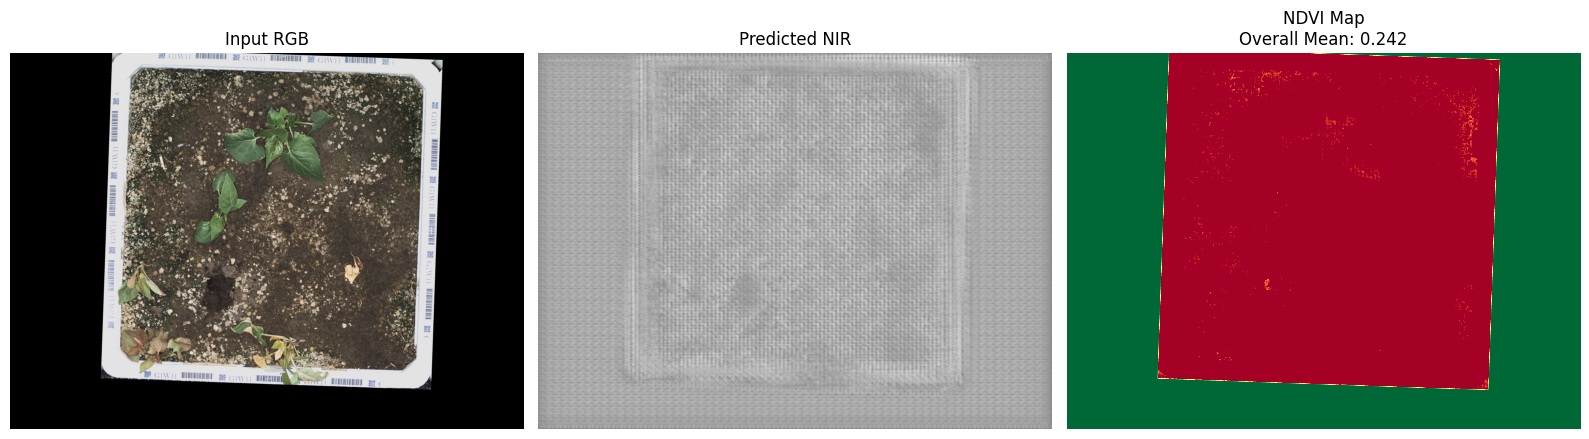

In [19]:
# ============================================================
# FIXED VERSION
# Similar output as your original:
# [Input RGB] [Predicted NIR] [NDVI Map]
#
# But now:
# Bright NIR on soil / road / dry path will NOT turn green.
# Only green vegetation gets boosted.
# ============================================================

import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt

# ================= SETTINGS =================
MODEL_PATH = "/kaggle/input/models/chitranshdamedhar/finetunedmodel-40-epoch/pytorch/default/1/finetuned_epoch40.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ================= MODEL =================
class EfficientUNetGenerator(nn.Module):
    def __init__(self, base_channels=40):
        super().__init__()
        bc = base_channels

        self.enc1 = self._down_block(3, bc)
        self.enc2 = self._down_block(bc, bc*2)
        self.enc3 = self._down_block(bc*2, bc*4)

        self.bottleneck = nn.Sequential(
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4),
            nn.ReLU(inplace=True),

            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4),
            nn.ReLU(inplace=True),
        )

        self.up3 = nn.ConvTranspose2d(bc*4, bc*2, 4, 2, 1)
        self.dec3 = self._up_block(bc*4, bc*2)

        self.up2 = nn.ConvTranspose2d(bc*2, bc, 4, 2, 1)
        self.dec2 = self._up_block(bc*2, bc)

        self.final = nn.Sequential(
            nn.ConvTranspose2d(bc, bc//2, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc//2, 1, 3, padding=1),
            nn.Tanh()
        )

    def _down_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 4, 2, 1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.2, inplace=True)
        )

    def _up_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)

        b = self.bottleneck(e3)

        d3 = torch.cat([self.up3(b), e2], dim=1)
        d3 = self.dec3(d3)

        d2 = torch.cat([self.up2(d3), e1], dim=1)
        d2 = self.dec2(d2)

        return self.final(d2)

# ================= LOAD MODEL =================
G = EfficientUNetGenerator(40).to(DEVICE)
G.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
G.eval()

# ================= MAIN =================
def test_image(image_path):

    rgb_pil = Image.open(image_path).convert("RGB")
    original = np.array(rgb_pil)
    h,w = original.shape[:2]

    transform = transforms.Compose([
        transforms.Resize((256,256)),
        transforms.ToTensor(),
        transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
    ])

    inp = transform(rgb_pil).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        pred = G(inp)
        pred_nir = (pred*0.5 + 0.5).clamp(0,1).squeeze().cpu().numpy()

    pred_nir = cv2.resize(pred_nir,(w,h))

        # ==========================================
    # Correct RGB channels
    # ==========================================
    R = original[:,:,0].astype(np.float32) / 255.0
    Gch = original[:,:,1].astype(np.float32) / 255.0
    B = original[:,:,2].astype(np.float32) / 255.0
    
    # vegetation confidence
    exg = 2*Gch - R - B
    exg = np.clip(exg, 0, 1)
    
    # corrected pseudo NIR
    nir_corrected = pred_nir * (0.25 + 0.75*exg)
    
    # TRUE NDVI
    ndvi = (nir_corrected - R) / (nir_corrected + R + 1e-6)
    ndvi = np.clip(ndvi, -1, 1)

    # ===================================================
    # DISPLAY (same style as yours)
    # ===================================================
    fig,axs = plt.subplots(1,3,figsize=(16,5))

    axs[0].imshow(original)
    axs[0].set_title("Input RGB")
    axs[0].axis("off")

    axs[1].imshow(pred_nir,cmap="gray",vmin=0,vmax=1)
    axs[1].set_title("Predicted NIR")
    axs[1].axis("off")

    axs[2].imshow(ndvi,cmap="RdYlGn",vmin=0,vmax=1)
    axs[2].set_title(f"NDVI Map\nOverall Mean: {np.mean(ndvi):.3f}")
    axs[2].axis("off")

    plt.tight_layout()
    plt.show()

# ================= RUN =================
image_path = "/kaggle/input/datasets/chitranshdamedhar/dired-leaf-also/testimg22.jpg"
test_image(image_path)

In [4]:
# ============================================================
# EVALUATION SCRIPT — RGB2NIR Pix2Pix Paired Format
# Splits paired image (RGB|NIR side by side), runs generator,
# computes PSNR, SSIM, MAE, NDVI MAE, NDVI R²
# ============================================================

import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import os
import pandas as pd
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import cv2

# ── paste your EfficientUNetGenerator class here ──
class EfficientUNetGenerator(nn.Module):
    def __init__(self, base_channels=40):
        super().__init__()
        bc = base_channels
        self.enc1 = self._down_block(3, bc)
        self.enc2 = self._down_block(bc, bc*2)
        self.enc3 = self._down_block(bc*2, bc*4)
        self.bottleneck = nn.Sequential(
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4), nn.ReLU(inplace=True),
            nn.Conv2d(bc*4, bc*4, 3, padding=1, bias=False),
            nn.BatchNorm2d(bc*4), nn.ReLU(inplace=True),
        )
        self.up3  = nn.ConvTranspose2d(bc*4, bc*2, 4, 2, 1)
        self.dec3 = self._up_block(bc*4, bc*2)
        self.up2  = nn.ConvTranspose2d(bc*2, bc, 4, 2, 1)
        self.dec2 = self._up_block(bc*2, bc)
        self.final = nn.Sequential(
            nn.ConvTranspose2d(bc, bc//2, 4, 2, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(bc//2, 1, 3, padding=1),
            nn.Tanh()
        )

    def _down_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.LeakyReLU(0.2, inplace=True),
        )

    def _up_block(self, in_ch, out_ch):
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        b  = self.bottleneck(e3)
        d3 = self.dec3(torch.cat([self.up3(b), e2], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e1], 1))
        return self.final(d2)

# ============================================================
# SETTINGS — edit these
# ============================================================
MODEL_PATH  = "/kaggle/input/models/chitranshdamedhar/rgb2nir-generator-pth/pytorch/default/1/rgb2nir_generator_epoch60.pth"
TEST_DIR    = "/kaggle/working/pix2pix_rgb2nir/pytorch-CycleGAN-and-pix2pix/datasets/rgb2nir/test"
OUTPUT_DIR  = "/content/eval_results"
MAX_IMAGES  = 50   # set to None to run on full test set
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
G = EfficientUNetGenerator(base_channels=40).to(DEVICE)
G.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
G.eval()
print(f"Model loaded on {DEVICE}")

tile_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

# ============================================================
# SPLIT PAIRED IMAGE → RGB + NIR
# Your format: horizontal stack, RGB left, NIR right
# ============================================================
def split_paired(paired_path):
    img = cv2.imread(paired_path)
    if img is None:
        return None, None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    w   = img.shape[1] // 2
    rgb = img[:, :w,  :]   # left half
    nir = img[:, w:,  :]   # right half
    # NIR was saved as COLOR_GRAY2BGR so all 3 channels are identical
    # take just one channel
    nir_gray = nir[:, :, 0].astype(np.float32) / 255.0
    return rgb, nir_gray

# ============================================================
# PREDICT NIR FROM RGB (resize to 256, predict, resize back)
# ============================================================
def predict_nir(rgb_np):
    h, w   = rgb_np.shape[:2]
    img256 = np.array(Image.fromarray(rgb_np).resize((256, 256)))
    inp    = tile_tf(Image.fromarray(img256)).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = (G(inp) * 0.5 + 0.5).clamp(0, 1).squeeze().cpu().numpy()
    pred_full = np.array(
        Image.fromarray((pred * 255).astype(np.uint8)).resize((w, h))
    ).astype(np.float32) / 255.0
    return pred_full

def compute_ndvi(nir, red):
    return np.clip((nir - red) / (nir + red + 1e-6), -1, 1)

# ============================================================
# MAIN EVALUATION LOOP
# ============================================================
files = sorted([
    f for f in os.listdir(TEST_DIR)
    if f.lower().endswith(('.png', '.jpg', '.jpeg'))
])
if MAX_IMAGES:
    files = files[:MAX_IMAGES]

print(f"Evaluating on {len(files)} test images...\n")

results  = []
all_nir_gt   = []
all_nir_pred = []

for fname in files:
    path = os.path.join(TEST_DIR, fname)
    rgb, nir_gt = split_paired(path)

    if rgb is None:
        print(f"  Skipping {fname} — failed to load")
        continue

    nir_pred = predict_nir(rgb)

    # Resize gt to match pred if needed
    if nir_gt.shape != nir_pred.shape:
        nir_gt = np.array(
            Image.fromarray((nir_gt*255).astype(np.uint8)).resize(
                (nir_pred.shape[1], nir_pred.shape[0]))
        ).astype(np.float32) / 255.0

    # ── Per-image metrics ──
    p    = psnr(nir_gt, nir_pred, data_range=1.0)
    s    = ssim(nir_gt, nir_pred, data_range=1.0)
    mae  = float(np.mean(np.abs(nir_gt - nir_pred)))

    red_norm  = rgb[:,:,0].astype(np.float32) / 255.0
    ndvi_gt   = compute_ndvi(nir_gt,   red_norm)
    ndvi_pred = compute_ndvi(nir_pred, red_norm)
    ndvi_mae  = float(np.mean(np.abs(ndvi_gt - ndvi_pred)))

    corr, _ = pearsonr(ndvi_gt.flatten(), ndvi_pred.flatten())
    r2      = corr ** 2

    results.append({
        "Image"    : fname,
        "PSNR(dB)" : round(p,    2),
        "SSIM"     : round(s,    4),
        "NIR MAE"  : round(mae,  4),
        "NDVI MAE" : round(ndvi_mae, 4),
        "NDVI R²"  : round(r2,   4),
    })

    all_nir_gt.extend(ndvi_gt.flatten()[::10].tolist())    # subsample for scatter
    all_nir_pred.extend(ndvi_pred.flatten()[::10].tolist())

    print(f"  {fname}: PSNR={p:.2f}dB | SSIM={s:.4f} | "
          f"NIR MAE={mae:.4f} | NDVI MAE={ndvi_mae:.4f} | R²={r2:.4f}")

# ============================================================
# SUMMARY
# ============================================================
df = pd.DataFrame(results)
summary = df[["PSNR(dB)","SSIM","NIR MAE","NDVI MAE","NDVI R²"]].mean().round(4)

print("\n" + "="*60)
print("MEAN METRICS ACROSS TEST SET")
print("="*60)
for k, v in summary.items():
    print(f"  {k:<12}: {v}")
print("="*60)

df.to_csv(f"{OUTPUT_DIR}/test_metrics.csv", index=False)
print(f"\nPer-image CSV saved → {OUTPUT_DIR}/test_metrics.csv")

# ============================================================
# FIGURE 1 — Visual quality check on first 3 images
# ============================================================
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
sample_files = files[:3]

for row, fname in enumerate(sample_files):
    rgb, nir_gt  = split_paired(os.path.join(TEST_DIR, fname))
    nir_pred     = predict_nir(rgb)
    red_norm     = rgb[:,:,0].astype(np.float32)/255.0
    error_map    = np.abs(nir_gt - nir_pred)

    axes[row,0].imshow(rgb)
    axes[row,0].set_title("Input RGB",        fontsize=11, fontweight='bold')
    axes[row,0].axis('off')

    axes[row,1].imshow(nir_gt,   cmap='gray')
    axes[row,1].set_title("Ground Truth NIR", fontsize=11)
    axes[row,1].axis('off')

    axes[row,2].imshow(nir_pred, cmap='gray')
    axes[row,2].set_title("Predicted NIR",    fontsize=11)
    axes[row,2].axis('off')

    im = axes[row,3].imshow(error_map, cmap='hot', vmin=0, vmax=0.3)
    axes[row,3].set_title("Error Map |GT−Pred|", fontsize=11)
    axes[row,3].axis('off')
    plt.colorbar(im, ax=axes[row,3], fraction=0.046)

plt.suptitle("NIR Prediction Quality — Sample Test Images",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/visual_quality.jpg", dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# FIGURE 2 — NDVI scatter: predicted vs ground truth
# ============================================================
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(all_nir_gt, all_nir_pred, alpha=0.05, s=1, color='steelblue')
ax.plot([-1,1],[-1,1], 'r--', linewidth=1.5, label='Perfect prediction')
overall_corr, _ = pearsonr(all_nir_gt, all_nir_pred)
ax.set_xlabel("Ground Truth NDVI",  fontsize=12)
ax.set_ylabel("Predicted NDVI",     fontsize=12)
ax.set_title(f"NDVI: Predicted vs Ground Truth\nR²={overall_corr**2:.4f}",
             fontsize=13, fontweight='bold')
ax.legend()
ax.set_xlim(-1, 1); ax.set_ylim(-1, 1)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/ndvi_scatter.jpg", dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# FIGURE 3 — Metrics distribution across test set
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics_to_plot = ["PSNR(dB)", "SSIM", "NDVI R²"]
colors = ["steelblue", "seagreen", "tomato"]

for ax, metric, color in zip(axes, metrics_to_plot, colors):
    ax.hist(df[metric], bins=20, color=color, edgecolor='white', alpha=0.85)
    ax.axvline(df[metric].mean(), color='black', linestyle='--',
               linewidth=1.5, label=f'Mean={df[metric].mean():.3f}')
    ax.set_title(metric, fontsize=13, fontweight='bold')
    ax.set_xlabel("Value"); ax.set_ylabel("Count")
    ax.legend(fontsize=10)

plt.suptitle("Metric Distributions Across Test Set",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/metric_distributions.jpg", dpi=150, bbox_inches='tight')
plt.show()

print("\nAll outputs saved to:", OUTPUT_DIR)
print("Screenshots for slide 6:")
print("  → test_metrics.csv  (summary table)")
print("  → visual_quality.jpg (RGB | GT NIR | Pred NIR | Error)")
print("  → ndvi_scatter.jpg   (R² scatter plot)")
print("  → metric_distributions.jpg (histograms)")

RuntimeError: Error(s) in loading state_dict for EfficientUNetGenerator:
	Missing key(s) in state_dict: "enc1.0.weight", "enc1.1.weight", "enc1.1.bias", "enc1.1.running_mean", "enc1.1.running_var", "enc2.0.weight", "enc2.1.weight", "enc2.1.bias", "enc2.1.running_mean", "enc2.1.running_var", "enc3.0.weight", "enc3.1.weight", "enc3.1.bias", "enc3.1.running_mean", "enc3.1.running_var", "bottleneck.0.weight", "bottleneck.1.weight", "bottleneck.1.bias", "bottleneck.1.running_mean", "bottleneck.1.running_var", "bottleneck.3.weight", "bottleneck.4.weight", "bottleneck.4.bias", "bottleneck.4.running_mean", "bottleneck.4.running_var", "up3.weight", "up3.bias", "dec3.0.weight", "dec3.1.weight", "dec3.1.bias", "dec3.1.running_mean", "dec3.1.running_var", "dec3.3.weight", "dec3.4.weight", "dec3.4.bias", "dec3.4.running_mean", "dec3.4.running_var", "up2.weight", "up2.bias", "dec2.0.weight", "dec2.1.weight", "dec2.1.bias", "dec2.1.running_mean", "dec2.1.running_var", "dec2.3.weight", "dec2.4.weight"